> **In this repository.** Fine-tuning experiment log for one pretrained backbone. Notebooks 05 to 13 are copies of one shared template: the data, model, metric and training code is the same in each, and only the backbone, its settings and the iterations differ. Each `run_iteration` cell trains one change on `train.csv` and scores it on `val.csv`; the cell after it records the team's accept/reject decision. `test.csv` and `test_unseen.csv` are never read here. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# Fine-tuning experiments: SigLip 2

Fine-tuning experiments: SigLIP 2 ViT-B/16
SigLIP 2 ViT-B/16 image tower (about 93M parameters, trained on WebLI image–text pairs), with its attention-pooling (MAP) head producing 768-d features.

The notebook implements an experiment design on the final dataset (`downloaded_data/inat_dataset_final`). It trains on `train.csv`, tunes and evaluates on `val.csv`, and **never touches `test.csv` or `test_unseen.csv`**.

## How the notebook is organized

* **Section 1** holds `MODEL_NAME` and `BASE_CONFIG`, an initial configuration. This should be edited to specify the model and hyperparameters.
* **Sections 2 to 6** (data, backbone adapters, metrics, plots, training loop) are shared code and should be identical in every model's notebook so the metrics are comparable.
* **Section 7** is the manual iteration loop: one cell runs an iteration (`run_iteration(name, overrides)`), the next cell records your decision (`accept(name)` or `reject(name)`). Accepted overrides become part of the current configuration, and every later iteration is run on top of it. Decisions are saved in `RUNS_DIR/<MODEL_NAME>/decisions.json`, so the configuration survives a kernel restart.
* Cross-iteration and cross-model comparison lives in `18_final_model_comparison.ipynb` next to this file; it reads the files each run writes.

## Task encoding

* The head has **one logit per invasive species** (40 classes). `not_invasive` rows have an all-zero target.
* Loss: multi-label `BCEWithLogitsLoss`.
* Binary "is invasive" = `max_c sigmoid(logit_c) >= threshold`; species = `argmax_c` when invasive, else `not_invasive`.
* The threshold is tuned on the validation set to maximize **macro-F1 over the 40 invasive species** (the primary validation metric). All thresholded metrics use that fixed threshold.
* Primary KPI: top-1 accuracy over all 41 labels.

## Outputs

Each iteration writes to `RUNS_DIR/<MODEL_NAME>/<iteration>/`: `config.json` (the effective hyperparameters and the accepted changes it was built on), `history.csv` (per-epoch metrics), `best.pt` (best validation checkpoint by macro-F1, with its threshold), `metrics_final.json` (best checkpoint re-evaluated with TTA), `val_predictions.csv`, and the plots as PNG.

## 0. Environment

In [ ]:
import importlib.util, os, subprocess, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")

# Install what is missing (Colab ships torch/torchvision/sklearn/pandas/matplotlib already).
_required = {"torchmetrics": "torchmetrics", "timm": "timm", "huggingface_hub": "huggingface_hub",
             "transformers": "transformers>=4.57.3", "open_clip": "open_clip_torch"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

# DINOv3 needs transformers >= 4.57.3 (PlantNet's own requirements.txt). Upgrade if the class is absent.
import transformers
if importlib.util.find_spec("transformers.models.dinov3_vit") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U", "transformers>=4.57.3"])
    print("transformers upgraded; RESTART THE RUNTIME and run again.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import copy, datetime, json, math, random, re, shutil, time, warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from torchvision.transforms import v2
import torchmetrics
from torchmetrics.classification import MulticlassF1Score, MulticlassAccuracy, MulticlassConfusionMatrix
from tqdm.auto import tqdm
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             precision_score, recall_score, f1_score)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if (DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8) else torch.float16   # native bf16 needs Ampere+ (A100/L4); T4 -> fp16
print(f"torch {torch.__version__} | transformers {transformers.__version__} | torchmetrics {torchmetrics.__version__}")
print(f"device: {DEVICE} | mixed-precision dtype: {AMP_DTYPE if DEVICE.type == 'cuda' else 'disabled (CPU)'}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0), f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GiB")

# Plot style shared by every notebook so figures are comparable across models.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_ORANGE, C_GRAY = "#2a78d6", "#eb6834", "#9a9995"

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

torch 2.11.0+cu130 | transformers 5.22.0 | torchmetrics 1.9.0
device: cuda | mixed-precision dtype: torch.bfloat16
NVIDIA RTX PRO 6000 Blackwell Server Edition 95.0 GiB


## 1. Configuration

`BASE_CONFIG` is the initial configuration. Iterations (Section 7) pass a `dict` of overrides; the effective configuration of an iteration is `{**current_configuration, **overrides}`, where the current configuration is `BASE_CONFIG` plus every accepted override so far.

In [ ]:
MODEL_NAME = "siglip2_base"       # key of BACKBONE_REGISTRY (Section 3)

# Leave both as None to use the Team Drive path on Colab or the repo-relative path locally.
DATA_ROOT_OVERRIDE = None                    # e.g. "/path/to/downloaded_data/inat_dataset_final"
RUNS_DIR_OVERRIDE = None                     # e.g. "/path/to/modeling_runs"; default: <repo root>/modeling_runs

BASE_CONFIG = {
    # --- data / input ---
    "image_size": 224,                        # network input (design: 224x224)
    "presize": 256,                           # shorter side before the random crop; keeps aspect ratio
    "rrc_scale": (0.75, 1.0),                 # RandomResizedCrop(224, scale=...)
    "hflip_p": 0.5,
    "rotation_deg": 15,                       # RandomRotation(+-15 deg)
    "color_jitter": {"brightness": 0.15, "contrast": 0.15, "saturation": 0.15, "hue": 0.02},
    "val_resize": 256,                        # eval: Resize(shorter side) then CenterCrop(image_size)
    "batch_size": 64,                         # reduce to 32/16 if the GPU runs out of memory
    "num_workers": 2,
    # --- architecture: backbone -> pooled features -> dropout -> linear(n_invasive) ---
    "dropout": 0.1,
    "backbone_kwargs": {"drop_path_rate": 0.0},   # stochastic depth inside the ViT blocks
    # --- stage 1: frozen backbone, constant LR on the head ---
    "frozen_epochs": 3,
    "frozen_head_lr": 1e-3,
    # --- stage 2: full fine-tuning, 1-cycle cosine schedule ---
    "full_epochs": 20,
    "backbone_lr": 2e-5,                      # peak LR of the backbone (model dependent)
    "head_lr": 3e-4,                          # peak LR of the head
    "pct_start": 0.1,
    "weight_decay": 0.01,
    "weight_decay_exclude_1d": True,          # no decay on biases, norm parameters and the CLS/register/mask tokens
    "layer_decay": None,                      # layer-wise LR decay factor for the backbone blocks (None = off; e.g. 0.8)
    "grad_clip_norm": 1.0,
    "amp": True,                              # mixed precision (bf16 if the GPU supports it, else fp16)
    # --- loss / regularization ---
    "loss": "bce",                            # multi-label BCEWithLogitsLoss over the invasive classes
    "bce_pos_weight": None,                   # None = plain BCE; a float scales the positive term (imbalance)
    "label_smoothing": 0.0,                   # BCE targets -> y*(1-eps) + eps/2
    "mixup_alpha": 0.0,                       # 0 = off
    # --- evaluation ---
    "threshold_grid": [round(t, 3) for t in np.linspace(0.01, 0.99, 99)],
    "select_metric": "macro_f1_invasive",     # checkpoint selection + threshold tuning target
    "tta_hflip": True,                        # test-time augmentation for the final evaluation of best.pt
    # --- bookkeeping ---
    "seed": 42,
    "max_batches_per_epoch": None,            # set e.g. 5 to check the pipeline quickly before a real run
}

## 2. Paths and data

The dataset folder is `DATA_ROOT_OVERRIDE` if set, else the Team Drive path on Colab, else the repo-relative path. Only `train.csv` and `val.csv` are read. The last cell of this section decodes every image once into RAM (about 2.4 GB); all iterations train from that cache.

In [ ]:
_candidates = [DATA_ROOT_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final",
               "../../downloaded_data/inat_dataset_final", "downloaded_data/inat_dataset_final"]
DATA_ROOT = next((Path(p) for p in _candidates if p and (Path(p) / "train.csv").exists()), None)
assert DATA_ROOT is not None, f"dataset folder not found; tried {_candidates}"
RUNS_DIR = Path(RUNS_DIR_OVERRIDE) if RUNS_DIR_OVERRIDE else DATA_ROOT.parent.parent / "modeling_runs"
MODEL_DIR = RUNS_DIR / MODEL_NAME
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_ROOT:", DATA_ROOT.resolve()); print("MODEL_DIR:", MODEL_DIR.resolve())

NONE_LABEL = "not_invasive"
train_df = pd.read_csv(DATA_ROOT / "train.csv")
val_df = pd.read_csv(DATA_ROOT / "val.csv")

INVASIVE_CLASSES = sorted(c for c in train_df["label"].unique() if c != NONE_LABEL)
N_INVASIVE = len(INVASIVE_CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(INVASIVE_CLASSES)}
CLASS_TO_IDX[NONE_LABEL] = N_INVASIVE                   # index N_INVASIVE = not_invasive (no logit, only a target)
ALL_LABELS = INVASIVE_CLASSES + [NONE_LABEL]            # 41 names in index order
assert set(val_df["label"]) <= set(ALL_LABELS), "val has labels that train does not"
assert not set(train_df["observer_id"]) & set(val_df["observer_id"]), "observer leakage between train and val"

for name, df in (("train", train_df), ("val", val_df)):
    df["y"] = df["label"].map(CLASS_TO_IDX)
    print(f"{name}: {len(df):>5} rows | {df['invasive'].sum():>4} invasive | {(~df['invasive']).sum():>4} {NONE_LABEL} | "
          f"{df.loc[df['invasive'], 'label'].nunique()} invasive classes, {df['scientific_name'].nunique()} species")
print(f"{N_INVASIVE} invasive classes -> {N_INVASIVE} logits; '{NONE_LABEL}' is the all-zero target (index {N_INVASIVE})")

DATA_ROOT: /content/drive/MyDrive/fall-2026-DL-invasive-plants/downloaded_data/inat_dataset_final
MODEL_DIR: /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base
train:  7342 rows | 1186 invasive | 6156 not_invasive | 40 invasive classes, 441 species
val:  3228 rows |  982 invasive | 2246 not_invasive | 40 invasive classes, 441 species
40 invasive classes -> 40 logits; 'not_invasive' is the all-zero target (index 40)


In [ ]:
# Check which image files exist (the download may have gaps; see download_failures.csv).
_failures_file = DATA_ROOT / "download_failures.csv"
if _failures_file.exists():
    try:
        _f = pd.read_csv(_failures_file)
        print(f"download_failures.csv: {len(_f)} rows")
    except pd.errors.EmptyDataError:                 # the download cell writes an empty file when nothing failed
        print("download_failures.csv exists but is empty: no failed downloads")

for name, df in (("train", train_df), ("val", val_df)):
    df["exists"] = df["image_path"].map(lambda p: (DATA_ROOT / p).is_file())
    n_missing = (~df["exists"]).sum()
    if n_missing:
        missing_by_class = df.loc[~df["exists"], "label"].value_counts()
        print(f"{name}: {n_missing} rows without an image file (dropped). Worst classes:\n{missing_by_class.head(8).to_string()}")
    else:
        print(f"{name}: all {len(df)} image files present")
train_df = train_df[train_df["exists"]].reset_index(drop=True)
val_df = val_df[val_df["exists"]].reset_index(drop=True)
assert len(train_df) and len(val_df), "no images found under DATA_ROOT; is Drive mounted / are the images downloaded?"

download_failures.csv exists but is empty: no failed downloads
train: all 7342 image files present
val: all 3228 image files present


In [ ]:
# Decode every train/val image ONCE and keep it in RAM as uint8: training images resized to the shorter side `presize`
# (aspect ratio kept, so they have different sizes and are stored ragged in one flat tensor), validation images already
# resized and center-cropped. Each epoch then only applies the random crop / flip / rotation / jitter to small tensors
# instead of decoding 10k JPEGs again; the per-epoch time on Colab drops from minutes to tens of seconds. Nothing is
# written to disk: the cache lives in RAM and is rebuilt once per kernel.


class _Decode(Dataset):
    # one-off decode + deterministic resize; wrapped in a DataLoader only to use several worker processes
    def __init__(self, paths, tf):
        self.paths, self.tf = list(paths), tf

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = ImageOps.exif_transpose(Image.open(DATA_ROOT / self.paths[i])).convert("RGB")
        return T.functional.pil_to_tensor(self.tf(img))                  # uint8, C x H x W


def decode_all(paths, tf, desc):
    dl = DataLoader(_Decode(paths, tf), batch_size=None, num_workers=BASE_CONFIG["num_workers"],   # batch_size=None: items stay ragged
                    generator=torch.Generator().manual_seed(0))                                     # do not touch the global RNG
    return [t for t in tqdm(dl, total=len(paths), desc=desc, unit="img", leave=False)]


class RaggedUint8:
    """Images of different sizes in ONE flat uint8 tensor plus shapes and offsets. A single allocation is shared copy-on-write
    by the forked DataLoader workers, whereas a Python list of thousands of tensors slowly gets duplicated into every worker."""
    def __init__(self, flat, shapes, offsets):
        self.flat, self.shapes, self.offsets = flat, shapes, offsets

    @classmethod
    def from_list(cls, tensors):
        shapes = torch.tensor([list(t.shape) for t in tensors])
        offsets = torch.cat([torch.zeros(1, dtype=torch.long), shapes.prod(1).cumsum(0)])
        return cls(torch.cat([t.flatten() for t in tensors]), shapes, offsets)

    def __len__(self):
        return len(self.shapes)

    def __getitem__(self, i):
        return self.flat[self.offsets[i]:self.offsets[i + 1]].view(*self.shapes[i].tolist())


_IMAGE_CACHES = {}

def image_caches(cfg):
    """(train images at presize, val crops of image_size) for this configuration's sizes. Built once per kernel and reused by
    every iteration; rebuilt only if an iteration changes presize, val_resize or image_size."""
    key = (cfg["presize"], cfg["val_resize"], cfg["image_size"])
    if key in _IMAGE_CACHES:
        return _IMAGE_CACHES[key]
    t0 = time.time()
    train_images = RaggedUint8.from_list(decode_all(train_df["image_path"], T.Resize(cfg["presize"]), "decoding train images"))
    val_tf = T.Compose([T.Resize(cfg["val_resize"]), T.CenterCrop(cfg["image_size"])])
    val_images = torch.stack(decode_all(val_df["image_path"], val_tf, "decoding val images"))
    gb = (train_images.flat.numel() + val_images.numel()) / 2**30
    print(f"image cache: {len(train_images)} train images at presize {cfg['presize']} + {len(val_images)} val crops of "
          f"{cfg['image_size']}x{cfg['image_size']} = {gb:.2f} GB in RAM ({time.time() - t0:.0f}s)")
    _IMAGE_CACHES[key] = (train_images, val_images)
    return _IMAGE_CACHES[key]


image_caches(BASE_CONFIG)      # build now, so the time is spent here rather than inside the first iteration


decoding train images:   0%|          | 0/7342 [00:00<?, ?img/s]

decoding val images:   0%|          | 0/3228 [00:00<?, ?img/s]

image cache: 7342 train images at presize 256 + 3228 val crops of 224x224 = 2.35 GB in RAM (3055s)
image cache saved to /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/_image_cache/cache_presize256_val256_size224.pt


## 3. Backbone adapters

A backbone adapter returns a `BackboneSpec`: an `nn.Module` whose `forward(x)` maps a normalized image batch to the **native pooled feature vector**, plus the feature dimension and the normalization constants of the checkpoint. The classifier (Section 3b) is identical for every backbone: `features -> Dropout(p) -> Linear(feat_dim, N_INVASIVE)`.

Adapters read `cfg["backbone_kwargs"]` for model-specific options. Implemented: the PlantNet DINOv3 ViT-S/16 and the plain DINOv3 ViT-S/16 (`pooling`, `drop_path_rate`); BioCLIP (ViT-B/16) and BioCLIP 2 (ViT-L/14) through `open_clip` (`features`: the projected CLIP image embedding, or the wider pre-projection token); SigLIP 2 ViT-B/16 and any other `timm` checkpoint (ResNet-18/50, ConvNeXt-Tiny; `drop_path_rate` where the architecture has it). `layer_decay` understands the block naming of all of them (`layer.N`, `blocks.N`, `resblocks.N`).

In [ ]:
@dataclass
class BackboneSpec:
    module: nn.Module          # forward(x) -> (B, feat_dim) pooled features
    feat_dim: int
    mean: tuple                # normalization of the checkpoint
    std: tuple
    notes: str = ""

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class HFPooledBackbone(nn.Module):
    # Wraps a HF vision model. pooling="cls": .pooler_output (DINOv3: final-normed CLS token).
    # pooling="cls+patchmean": CLS concatenated with the mean of the patch tokens (skips CLS + register tokens).
    def __init__(self, hf_model, pooling="cls", n_prefix_tokens=1):
        super().__init__(); self.m = hf_model; self.pooling = pooling; self.n_prefix = n_prefix_tokens
        assert pooling in ("cls", "cls+patchmean"), pooling
    def forward(self, x):
        out = self.m(pixel_values=x)
        if self.pooling == "cls":
            return out.pooler_output
        return torch.cat([out.pooler_output, out.last_hidden_state[:, self.n_prefix:].mean(1)], dim=1)


def build_plantnet_dinov3_vits(cfg) -> BackboneSpec:
    # PlantNet/plantnet-300k-v2-vits: DINOv3 ViT-S/16 encoder + 1000-way head in model.pth.
    # We rebuild the encoder architecture from config (ViT-S/16 with 4 register tokens; verified to load with
    # strict=True) so the gated facebook/dinov3-* weights are NOT needed; the encoder weights come from model.pth.
    # The 1000-class Pl@ntNet head is discarded.
    from huggingface_hub import snapshot_download
    from transformers import DINOv3ViTConfig, DINOv3ViTModel
    repo = snapshot_download("PlantNet/plantnet-300k-v2-vits", allow_patterns=["model.pth", "plantnet_config.json"])
    pn_cfg = json.load(open(Path(repo) / "plantnet_config.json"))
    ckpt = torch.load(Path(repo) / "model.pth", map_location="cpu", weights_only=True)
    bk = cfg.get("backbone_kwargs", {})
    pooling, drop_path = bk.get("pooling", "cls"), bk.get("drop_path_rate", 0.0)
    encoder = DINOv3ViTModel(DINOv3ViTConfig(hidden_size=384, num_hidden_layers=12, num_attention_heads=6,
                                             intermediate_size=1536, patch_size=16, num_register_tokens=4,
                                             image_size=cfg["image_size"], drop_path_rate=drop_path))
    encoder.load_state_dict(ckpt["encoder"], strict=True)
    feat_dim = pn_cfg["embedding_dim"] * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(encoder, pooling, n_prefix_tokens=1 + 4), feat_dim, tuple(pn_cfg["image_mean"]),
                        tuple(pn_cfg["image_std"]),
                        notes=f"PlantNet-300K-v2 fine-tuned DINOv3 ViT-S/16; PlantNet mean/std; pooling={pooling}, drop_path={drop_path}")


def build_dinov3_vits16(cfg) -> BackboneSpec:
    # Plain DINOv3 ViT-S/16 (self-supervised, LVD-1689M). Gated: accept the license on HF and `huggingface-cli login`.
    from transformers import AutoModel
    enc = AutoModel.from_pretrained("facebook/dinov3-vits16-pretrain-lvd1689m")
    pooling = cfg.get("backbone_kwargs", {}).get("pooling", "cls")
    feat_dim = enc.config.hidden_size * (2 if pooling == "cls+patchmean" else 1)
    return BackboneSpec(HFPooledBackbone(enc, pooling, 1 + enc.config.num_register_tokens), feat_dim, IMAGENET_MEAN, IMAGENET_STD,
                        notes=f"DINOv3 ViT-S/16, ImageNet mean/std, pooling={pooling}")


class TimmBackbone(nn.Module):
    def __init__(self, m):
        super().__init__(); self.m = m
    def forward(self, x):
        return self.m(x)                       # num_classes=0 -> pooled features


def build_timm(timm_name):
    # Any timm checkpoint, e.g. "resnet18.a1_in1k", "resnet50.a1_in1k", "convnext_tiny.fb_in22k_ft_in1k",
    # "vit_base_patch16_siglip_224.v2_webli" (the SigLIP 2 ViT-B/16 image tower with its attention-pooling head, 768-d).
    # backbone_kwargs["drop_path_rate"] is passed through when set (ViTs, ConvNeXt; ResNets ignore it).
    def _build(cfg) -> BackboneSpec:
        import timm
        drop_path = cfg.get("backbone_kwargs", {}).get("drop_path_rate", 0.0)
        kw = {"drop_path_rate": drop_path} if drop_path else {}
        m = timm.create_model(timm_name, pretrained=True, num_classes=0, **kw)   # drops the pretraining head, keeps the pooling
        dc = timm.data.resolve_data_config({}, model=m)
        return BackboneSpec(TimmBackbone(m), m.num_features, tuple(dc["mean"]), tuple(dc["std"]),
                            notes=f"timm {timm_name}, pool={getattr(m, 'global_pool', '?')}, drop_path={drop_path}")
    return _build


BACKBONE_REGISTRY = {
    "plantnet_dinov3_vits": build_plantnet_dinov3_vits,
    "dinov3_vits16": build_dinov3_vits16,
    "resnet18": build_timm("resnet18.a1_in1k"),
    "resnet50": build_timm("resnet50.a1_in1k"),
    "convnext_tiny": build_timm("convnext_tiny.fb_in22k_ft_in1k"),                   # ViT-L/14, 304M params, 768-d embedding
    "siglip2_base": build_timm("vit_base_patch16_siglip_224.v2_webli"),      # SigLIP 2 ViT-B/16, 93M params, 768-d MAP features
}
assert MODEL_NAME in BACKBONE_REGISTRY, f"{MODEL_NAME!r} not in {list(BACKBONE_REGISTRY)}"


### 3b. Classifier: backbone -> pooled features -> Dropout -> Linear
Head initialized with Xavier-uniform weights and zero biases. No new BatchNorm layers.

In [ ]:
class InvasiveClassifier(nn.Module):
    def __init__(self, spec: BackboneSpec, n_classes: int, dropout: float):
        super().__init__()
        self.backbone = spec.module
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(spec.feat_dim, n_classes)
        nn.init.xavier_uniform_(self.head.weight); nn.init.zeros_(self.head.bias)

    def forward(self, x):
        return self.head(self.dropout(self.backbone(x)))

    def set_backbone_frozen(self, frozen: bool):
        for p in self.backbone.parameters():
            p.requires_grad_(not frozen)


def build_model(cfg):
    spec = BACKBONE_REGISTRY[cfg["model_name"]](cfg)
    model = InvasiveClassifier(spec, N_INVASIVE, cfg["dropout"]).to(DEVICE)
    n_bb = sum(p.numel() for p in model.backbone.parameters()); n_head = sum(p.numel() for p in model.head.parameters())
    print(f"{cfg['model_name']}: backbone {n_bb/1e6:.1f}M params, head {n_head/1e3:.1f}K params, feat_dim {spec.feat_dim} | {spec.notes}")
    return model, spec

## 4. Dataset and transforms

The images come from the uint8 cache of Section 2. Train: `RandomResizedCrop(image_size, scale=rrc_scale)` from the image at `presize` (shorter side, aspect ratio preserved), horizontal flip, rotation, color jitter, normalize with the backbone's mean/std; the random augmentations are `torchvision.transforms.v2` on tensors, drawn per sample in the loader workers. Eval: the cached center crops (`val_resize` then `image_size`), normalized. Targets are multi-hot over the invasive classes.

In [ ]:
def make_transforms(cfg, spec: BackboneSpec):
    # Applied per sample to the cached uint8 tensors (Section 2) inside the DataLoader workers.
    norm = [v2.ToDtype(torch.float32, scale=True), v2.Normalize(spec.mean, spec.std)]
    cj = cfg["color_jitter"]
    train_tf = v2.Compose([
        v2.RandomResizedCrop(cfg["image_size"], scale=tuple(cfg["rrc_scale"]), antialias=True),   # from the presize image
        v2.RandomHorizontalFlip(p=cfg["hflip_p"]),
        v2.RandomRotation(cfg["rotation_deg"]),
        v2.ColorJitter(**cj),
        *norm])
    eval_tf = v2.Compose(norm)                   # the cached val images are already resized and center-cropped
    return train_tf, eval_tf


class InatImages(Dataset):
    def __init__(self, images, df: pd.DataFrame, transform, n_invasive: int):
        self.images = images                     # RaggedUint8 (train) or a stacked uint8 tensor (val), indexed like df
        self.y = df["y"].to_numpy(); self.transform = transform; self.n = n_invasive
        assert len(images) == len(df), "image cache does not match the dataframe"

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.transform(self.images[i])
        target = torch.zeros(self.n, dtype=torch.float32)
        if self.y[i] < self.n:
            target[self.y[i]] = 1.0                     # not_invasive stays all-zero
        return x, target, int(self.y[i])


def make_loaders(cfg, spec):
    train_tf, eval_tf = make_transforms(cfg, spec)
    train_images, val_images = image_caches(cfg)
    g = torch.Generator(); g.manual_seed(cfg["seed"])
    kw = dict(num_workers=cfg["num_workers"], pin_memory=DEVICE.type == "cuda", persistent_workers=cfg["num_workers"] > 0)
    train_dl = DataLoader(InatImages(train_images, train_df, train_tf, N_INVASIVE), batch_size=cfg["batch_size"],
                          shuffle=True, drop_last=True, generator=g, **kw)
    val_dl = DataLoader(InatImages(val_images, val_df, eval_tf, N_INVASIVE), batch_size=cfg["batch_size"] * 2,
                        shuffle=False, **kw)
    return train_dl, val_dl


def show_batch(dl, spec, n=12, title="training batch (augmented)"):
    x, _, y = next(iter(dl))
    mean, std = torch.tensor(spec.mean).view(3, 1, 1), torch.tensor(spec.std).view(3, 1, 1)
    cols = 6; rows = math.ceil(min(n, len(x)) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.2, rows * 2.4))
    for ax in axes.flat: ax.axis("off")
    for ax, xi, yi in zip(axes.flat, x[:n], y[:n]):
        ax.imshow((xi * std + mean).clamp(0, 1).permute(1, 2, 0).numpy())
        ax.set_title(ALL_LABELS[yi].replace(" ", "\n"), fontsize=7)
    fig.suptitle(title); fig.tight_layout(); plt.show()

## 5. Metrics (identical in every model notebook)

Inputs: `probs` of shape `(N, N_INVASIVE)` = sigmoid of the logits, and `y` in `0..N_INVASIVE` (`N_INVASIVE` = `not_invasive`).

| metric | definition |
|---|---|
| `macro_ap_invasive` | mean over the invasive classes of average precision (one-vs-rest, threshold-free) |
| `top1_recall_invasive`, `top3_recall_invasive` | among rows whose true label is invasive: is the true class the top-1 / within the top-3 ranked logits (threshold-free) |
| `threshold` | value of `t` on `threshold_grid` maximizing `macro_f1_invasive` on the validation set |
| `macro_f1_invasive` | **primary validation metric**: per-class F1 of the 41-way prediction (`argmax` if `max prob >= t` else `not_invasive`), averaged over the invasive classes only, computed on all rows |
| `top1_acc_all` | **primary KPI**: accuracy of the 41-way prediction over all rows |
| `bin_precision_invasive`, `bin_recall_invasive`, `bin_f1_invasive`, `bin_ap_invasive`, `bin_auroc_invasive` | binary "invasive vs not" with score `max prob` and threshold `t` |
| `noninv_precision`, `noninv_recall`, `noninv_auroc` | the same binary problem seen from the `not_invasive` side (positive = not invasive, score `1 - max prob`) |
| `per_class_f1`, `per_class_ap`, `confusion_matrix` | arrays for the plots and for `metrics_final.json` |

In [ ]:
def predict_not_invasive(probs: np.ndarray, t: float) -> np.ndarray:
    # Species when the strongest invasive probability clears t, otherwise not_invasive.
    pred = probs.argmax(1)
    pred[probs.max(1) < t] = N_INVASIVE
    return pred


def macro_f1_invasive(y: np.ndarray, pred: np.ndarray) -> float:
    f1 = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y))
    return float(f1[:N_INVASIVE].mean())


def tune_threshold(probs, y, grid):
    # Sweep the grid; return the best t plus the full sweep for plotting.
    sweep = pd.DataFrame({"threshold": grid})
    sweep["macro_f1_invasive"] = [macro_f1_invasive(y, predict_not_invasive(probs, t)) for t in grid]
    sweep["top1_acc_all"] = [float((predict_not_invasive(probs, t) == y).mean()) for t in grid]
    best = sweep.loc[sweep["macro_f1_invasive"].idxmax()]
    return float(best["threshold"]), sweep


def compute_metrics(probs: np.ndarray, y: np.ndarray, threshold: float | None, grid) -> dict:
    probs = np.asarray(probs, dtype=np.float64); y = np.asarray(y)
    is_inv = y < N_INVASIVE
    onehot = np.eye(N_INVASIVE + 1)[y][:, :N_INVASIVE]              # (N, N_INVASIVE) binary targets

    m = {}
    # threshold-free, ranking metrics over the invasive classes
    per_class_ap = np.array([average_precision_score(onehot[:, c], probs[:, c]) if onehot[:, c].any() else np.nan
                             for c in range(N_INVASIVE)])
    m["macro_ap_invasive"] = float(np.nanmean(per_class_ap))
    if is_inv.any():
        rank = (-probs[is_inv]).argsort(1)
        m["top1_recall_invasive"] = float((rank[:, 0] == y[is_inv]).mean())
        m["top3_recall_invasive"] = float((rank[:, :3] == y[is_inv, None]).any(1).mean())
    # threshold
    sweep = None
    if threshold is None:
        threshold, sweep = tune_threshold(probs, y, grid)
    m["threshold"] = float(threshold)
    pred = predict_not_invasive(probs, threshold)
    # 41-way metrics at the fixed threshold
    f1_per_class = MulticlassF1Score(num_classes=N_INVASIVE + 1, average=None)(torch.as_tensor(pred), torch.as_tensor(y)).numpy()
    m["macro_f1_invasive"] = float(f1_per_class[:N_INVASIVE].mean())
    m["macro_f1_all41"] = float(f1_per_class.mean())
    m["top1_acc_all"] = float(MulticlassAccuracy(num_classes=N_INVASIVE + 1, average="micro")(torch.as_tensor(pred), torch.as_tensor(y)))
    # binary invasive detection
    score_inv = probs.max(1); pred_inv = pred < N_INVASIVE
    m["bin_precision_invasive"] = precision_score(is_inv, pred_inv, zero_division=0)
    m["bin_recall_invasive"] = recall_score(is_inv, pred_inv, zero_division=0)
    m["bin_f1_invasive"] = f1_score(is_inv, pred_inv, zero_division=0)
    m["bin_ap_invasive"] = average_precision_score(is_inv, score_inv)
    m["bin_auroc_invasive"] = roc_auc_score(is_inv, score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # the not_invasive side
    m["noninv_precision"] = precision_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_recall"] = recall_score(~is_inv, ~pred_inv, zero_division=0)
    m["noninv_auroc"] = roc_auc_score(~is_inv, 1 - score_inv) if 0 < is_inv.sum() < len(y) else np.nan
    # arrays
    m["per_class_f1"] = f1_per_class.tolist()
    m["per_class_ap"] = per_class_ap.tolist()
    m["confusion_matrix"] = MulticlassConfusionMatrix(num_classes=N_INVASIVE + 1)(torch.as_tensor(pred), torch.as_tensor(y)).numpy().tolist()
    m["_sweep"] = sweep; m["_pred"] = pred
    return m

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
                  "threshold", "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive",
                  "bin_auroc_invasive", "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]

def scalars(m: dict) -> dict:
    return {k: m[k] for k in SCALAR_METRICS if k in m}

### 5b. Plots

In [ ]:
def plot_training_curves(hist: pd.DataFrame, out_dir: Path, title=""):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    ax = axes[0]; ax.plot(hist["epoch"], hist["train_loss"], color=C_BLUE, lw=2, label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("training loss")
    ax = axes[1]; ax.plot(hist["epoch"], hist["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive, primary)")
    ax.plot(hist["epoch"], hist["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41 classes, KPI)")
    ax.plot(hist["epoch"], hist["macro_ap_invasive"], color=C_GRAY, lw=1.5, label="macro-AP (invasive)")
    ax.set_ylim(0, 1.15); ax.set_xlabel("epoch"); ax.set_title("validation metrics"); ax.legend(fontsize=7, loc="upper left", ncol=3, frameon=False)
    ax = axes[2]; ax.plot(hist["epoch"], hist["lr_head"], color=C_ORANGE, lw=2, label="head LR")
    ax.plot(hist["epoch"], hist["lr_backbone"], color=C_BLUE, lw=2, label="backbone LR")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title("learning rate (end of epoch; top block if layer decay)"); ax.legend(fontsize=7)
    for a in axes:
        if "frozen_epochs" in hist.attrs and hist.attrs["frozen_epochs"]:
            a.axvline(hist.attrs["frozen_epochs"] + 0.5, color=C_GRAY, ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "training_curves.png"); plt.show()


def plot_threshold_sweep(sweep: pd.DataFrame, t: float, out_dir: Path, title=""):
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(sweep["threshold"], sweep["macro_f1_invasive"], color=C_BLUE, lw=2, label="macro-F1 (invasive)")
    ax.plot(sweep["threshold"], sweep["top1_acc_all"], color=C_ORANGE, lw=2, label="top-1 accuracy (41)")
    ax.axvline(t, color=C_GRAY, ls="--", lw=1); ax.text(t, 0.02, f" t = {t:.2f}", fontsize=8)
    ax.set_xlabel("invasive threshold on max class probability"); ax.set_ylim(0, 1); ax.legend(fontsize=8)
    ax.set_title(title or "threshold sweep (validation)", fontsize=8); fig.tight_layout(); fig.savefig(out_dir / "threshold_sweep.png"); plt.show()


def plot_pr_roc(probs, y, m: dict, out_dir: Path, title=""):
    is_inv = y < N_INVASIVE; score = probs.max(1); t = m["threshold"]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    # binary PR curve: invasive vs not
    p, r, th = precision_recall_curve(is_inv, score)
    ax = axes[0]; ax.plot(r, p, color=C_BLUE, lw=2)
    ax.scatter([m["bin_recall_invasive"]], [m["bin_precision_invasive"]], color=C_ORANGE, s=40, zorder=3, label=f"operating point, t={t:.2f}")
    ax.axhline(is_inv.mean(), color=C_GRAY, ls=":", lw=1, label=f"prevalence {is_inv.mean():.2f}")
    ax.set_xlabel("recall (invasive)"); ax.set_ylabel("precision (invasive)"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"binary invasive detection: AP = {m['bin_ap_invasive']:.3f}"); ax.legend(fontsize=7, loc="lower left")
    # per-class PR curves
    ax = axes[1]
    for c in range(N_INVASIVE):
        yc = (y == c)
        if yc.any():
            pc, rc, _ = precision_recall_curve(yc, probs[:, c]); ax.plot(rc, pc, color=C_BLUE, alpha=0.25, lw=1)
    ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_title(f"per-class PR, {N_INVASIVE} invasive classes: macro-AP = {m['macro_ap_invasive']:.3f}")
    # ROC
    ax = axes[2]
    if 0 < is_inv.sum() < len(y):
        fpr, tpr, _ = roc_curve(is_inv, score); ax.plot(fpr, tpr, color=C_BLUE, lw=2)
        fpr_t = float((~is_inv & (score >= t)).sum() / max((~is_inv).sum(), 1))
        ax.scatter([fpr_t], [m["bin_recall_invasive"]], color=C_ORANGE, s=40, zorder=3)
    ax.plot([0, 1], [0, 1], color=C_GRAY, ls=":", lw=1)
    ax.set_xlabel("false-positive rate (not_invasive flagged)"); ax.set_ylabel("true-positive rate (invasive found)")
    ax.set_title(f"ROC: AUROC = {m['bin_auroc_invasive']:.3f}")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(out_dir / "pr_roc.png"); plt.show()


def plot_confusion(m: dict, out_dir: Path, title="", normalize=True):
    cm = np.array(m["confusion_matrix"], dtype=float)
    if normalize:
        cm = cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    fig, ax = plt.subplots(figsize=(11, 10))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(len(ALL_LABELS))); ax.set_yticks(range(len(ALL_LABELS)))
    ax.set_xticklabels(ALL_LABELS, rotation=90, fontsize=6); ax.set_yticklabels(ALL_LABELS, fontsize=6)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(title or ("confusion matrix, row-normalized (recall on the diagonal)" if normalize else "confusion matrix (counts)"))
    fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); fig.tight_layout(); fig.savefig(out_dir / "confusion_matrix.png"); plt.show()


def plot_per_class_f1(m: dict, out_dir: Path, support: pd.Series, title=""):
    f1 = pd.Series(m["per_class_f1"][:N_INVASIVE], index=INVASIVE_CLASSES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.22 * N_INVASIVE + 1.5))
    ax.barh(f1.index, f1.values, color=C_BLUE, height=0.7)
    for i, (name, v) in enumerate(f1.items()):
        ax.text(min(v + 0.01, 0.9), i, f"n={int(support.get(name, 0))}", va="center", fontsize=6, color="#52514e")
    ax.set_xlim(0, 1); ax.set_xlabel("F1 on validation (at the tuned threshold)"); ax.tick_params(axis="y", labelsize=7)
    ax.set_title(title or f"per-class F1; macro-F1 (invasive) = {m['macro_f1_invasive']:.3f}")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1.png"); plt.show()

## 6. Training loop

Two stages per iteration: `frozen_epochs` with the backbone frozen (constant `frozen_head_lr`, AdamW on the head only), then `full_epochs` of full fine-tuning with AdamW (`weight_decay`, not applied to 1-d parameters and tokens when `weight_decay_exclude_1d`), per-group peak LRs (`backbone_lr`, `head_lr`, optionally scaled per block by `layer_decay`) and a 1-cycle cosine schedule (`pct_start`). Mixed precision, gradient clipping at `grad_clip_norm`, gradient-norm logging, stop on a non-finite loss. The best epoch by `select_metric` on validation is kept as `best.pt`; no early stopping, no EMA. MixUp and label smoothing are off unless an iteration turns them on.

In [ ]:
def make_loss(cfg):
    pw = None if cfg["bce_pos_weight"] is None else torch.full((N_INVASIVE,), float(cfg["bce_pos_weight"]), device=DEVICE)
    return nn.BCEWithLogitsLoss(pos_weight=pw)


def apply_mixup_and_smoothing(x, target, cfg):
    eps = cfg["label_smoothing"]
    if eps > 0:
        target = target * (1 - eps) + 0.5 * eps
    if cfg["mixup_alpha"] > 0:
        lam = float(np.random.beta(cfg["mixup_alpha"], cfg["mixup_alpha"]))
        perm = torch.randperm(x.size(0), device=x.device)
        x = lam * x + (1 - lam) * x[perm]; target = lam * target + (1 - lam) * target[perm]
    return x, target


def train_one_epoch(model, dl, optimizer, scheduler, scaler, loss_fn, cfg, frozen: bool, desc: str = ""):
    model.train()
    if frozen:
        model.backbone.eval()                  # frozen stage: backbone statistics untouched (matters for BN backbones)
    use_amp = cfg["amp"] and DEVICE.type == "cuda"
    losses, gnorms = [], []
    n_batches = len(dl) if not cfg["max_batches_per_epoch"] else min(len(dl), cfg["max_batches_per_epoch"])
    bar = tqdm(dl, total=n_batches, desc=desc, leave=False, unit="batch")   # per-batch progress; disappears when the epoch ends
    for b, (x, target, _) in enumerate(bar):
        if cfg["max_batches_per_epoch"] and b >= cfg["max_batches_per_epoch"]:
            break
        x, target = x.to(DEVICE, non_blocking=True), target.to(DEVICE, non_blocking=True)
        x, target = apply_mixup_and_smoothing(x, target, cfg)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = model(x)
        loss = loss_fn(logits.float(), target)
        if not torch.isfinite(loss):
            raise RuntimeError(f"non-finite loss at batch {b}: {loss.item()}")
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        gnorm = torch.nn.utils.clip_grad_norm_([p for g in optimizer.param_groups for p in g["params"]], cfg["grad_clip_norm"])
        scaler.step(optimizer); scaler.update()
        if scheduler is not None:
            scheduler.step()
        losses.append(loss.item()); gnorms.append(float(gnorm))
        if b % 10 == 0 or b == n_batches - 1:
            bar.set_postfix(loss=f"{np.mean(losses[-10:]):.3f}", gnorm=f"{gnorms[-1]:.2f}",
                            lr_head=f"{optimizer.param_groups[0]['lr']:.1e}", refresh=False)
    bar.close()
    return float(np.mean(losses)), float(np.mean(gnorms)), float(np.max(gnorms))


@torch.no_grad()
def predict(model, dl, cfg, tta_hflip=False):
    model.eval(); use_amp = cfg["amp"] and DEVICE.type == "cuda"
    probs, ys = [], []
    for x, _, y in dl:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=use_amp):
            logits = model(x).float()
            if tta_hflip:
                logits = 0.5 * (logits + model(torch.flip(x, dims=[3])).float())
        probs.append(torch.sigmoid(logits).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


_LAYER_RE = re.compile(r"(?:^|\.)(?:layers?|blocks|resblocks)\.(\d+)\.")   # HF: layer.N | timm: blocks.N | open_clip: resblocks.N

def backbone_layer_id(name: str, n_layers: int) -> int:
    # 0 = embeddings / tokens, 1..n_layers = transformer blocks, n_layers + 1 = everything after (final norm, pooler).
    m = _LAYER_RE.search(name)
    if m:
        return int(m.group(1)) + 1
    if any(k in name for k in ("embed", "token", "conv1", "ln_pre")):   # patch/pos/CLS embeddings, open_clip stem
        return 0
    return n_layers + 1


def no_weight_decay(name: str, p: torch.Tensor) -> bool:
    return p.ndim <= 1 or name.endswith(".bias") or any(k in name for k in ("token", "pos_embed", "positional_embedding", "latent"))


def param_groups(model, cfg, frozen_stage=False):
    # Groups by (role, layer id, decay/no-decay). LR per group: head_lr for the head; backbone_lr * layer_decay^(n_layers + 1 - id)
    # for the backbone when layer_decay is set. Weight decay only on >= 2-d weights when weight_decay_exclude_1d.
    wd, excl = cfg["weight_decay"], cfg["weight_decay_exclude_1d"]
    groups = {}
    def add(key, p, lr, decay, name):
        g = groups.setdefault(key, {"params": [], "lr": lr, "weight_decay": wd if decay else 0.0, "name": name})
        g["params"].append(p)
    head_lr = cfg["frozen_head_lr"] if frozen_stage else cfg["head_lr"]
    for n, p in model.head.named_parameters():
        decay = not (excl and no_weight_decay(n, p))
        add(("head", decay), p, head_lr, decay, "head")
    if not frozen_stage:
        names = [n for n, _ in model.backbone.named_parameters()]
        ids = [int(m.group(1)) for n in names for m in [_LAYER_RE.search(n)] if m]
        n_layers = (max(ids) + 1) if ids else 0
        for n, p in model.backbone.named_parameters():
            lid = backbone_layer_id(n, n_layers)
            scale = (cfg["layer_decay"] ** (n_layers + 1 - lid)) if cfg["layer_decay"] else 1.0
            decay = not (excl and no_weight_decay(n, p))
            add(("backbone", lid, decay), p, cfg["backbone_lr"] * scale, decay, f"backbone_l{lid}")
    return list(groups.values())


def describe_param_groups(groups):
    rows = [{"group": g["name"], "lr": g["lr"], "weight_decay": g["weight_decay"], "n_params": sum(p.numel() for p in g["params"])} for g in groups]
    return pd.DataFrame(rows).groupby(["group", "lr", "weight_decay"], as_index=False)["n_params"].sum().sort_values(["group", "lr"])


def train_and_evaluate(cfg: dict, out_dir: Path, show_plots=True, show_batch_preview=False) -> dict:
    # Trains one configuration, writes every artifact to out_dir, returns the summary row (scalar metrics of best.pt with TTA).
    name = cfg["iteration"]
    seed_everything(cfg["seed"])
    model, spec = build_model(cfg)
    train_dl, val_dl = make_loaders(cfg, spec)
    if show_batch_preview:
        rng = (torch.get_rng_state(), np.random.get_state(), random.getstate())
        show_batch(train_dl, spec)               # the preview consumes random state (augmentations, loader shuffle);
        torch.set_rng_state(rng[0]); np.random.set_state(rng[1]); random.setstate(rng[2])   # restore it and rebuild the
        train_dl, val_dl = make_loaders(cfg, spec)                                          # loaders so every iteration
    loss_fn = make_loss(cfg)                                                                # sees the same stream
    use_scaler = cfg["amp"] and DEVICE.type == "cuda" and AMP_DTYPE == torch.float16
    scaler = torch.amp.GradScaler(enabled=use_scaler)
    history, best_score, best_epoch = [], -1.0, -1
    steps_per_epoch = len(train_dl) if not cfg["max_batches_per_epoch"] else min(len(train_dl), cfg["max_batches_per_epoch"])
    n_epochs_total = cfg["frozen_epochs"] + cfg["full_epochs"]
    print(f"{n_epochs_total} epochs ({cfg['frozen_epochs']} frozen + {cfg['full_epochs']} full) x {steps_per_epoch} batches of "
          f"{cfg['batch_size']} | validation: {len(val_dl.dataset)} images in {len(val_dl)} batches")
    t_start = time.time()

    def eta(stage):
        # remaining epochs of the current stage at this stage's mean epoch time; the full stage is slower than the frozen one
        done = [r["seconds"] for r in history if r["stage"] == stage]
        n_stage = cfg["frozen_epochs"] if stage == "frozen" else cfg["full_epochs"]
        left = (n_stage - len(done)) * float(np.mean(done))
        tail = " + full stage" if stage == "frozen" and cfg["full_epochs"] else ""
        return f"elapsed {(time.time() - t_start) / 60:.1f}m, ~{left / 60:.1f}m left in {stage} stage{tail}"

    def evaluate_and_log(epoch, stage, train_loss, gnorm_mean, gnorm_max, optimizer, t0):
        nonlocal best_score, best_epoch
        probs, y = predict(model, val_dl, cfg)
        m = compute_metrics(probs, y, None, cfg["threshold_grid"])
        lr_bb = max([g["lr"] for g in optimizer.param_groups if g["name"].startswith("backbone")], default=0.0)
        lr_head = max(g["lr"] for g in optimizer.param_groups if g["name"] == "head")
        row = {"epoch": epoch, "stage": stage, "train_loss": train_loss, "grad_norm_mean": gnorm_mean, "grad_norm_max": gnorm_max,
               "lr_backbone": lr_bb, "lr_head": lr_head, "seconds": time.time() - t0, **scalars(m)}
        history.append(row)
        score = m[cfg["select_metric"]]
        flag = ""
        if score > best_score:
            best_score, best_epoch, flag = score, epoch, " *best*"
            torch.save({"state_dict": model.state_dict(), "epoch": epoch, "threshold": m["threshold"], "config": cfg}, out_dir / "best.pt")
        print(f"ep {epoch:>2}/{n_epochs_total} [{stage:<6}] loss {train_loss:.4f} | val macro-F1 {m['macro_f1_invasive']:.4f} "
              f"top1 {m['top1_acc_all']:.4f} mAP {m['macro_ap_invasive']:.4f} t={m['threshold']:.2f} | gnorm {gnorm_mean:.2f} | "
              f"{row['seconds']:.0f}s | {eta(stage)}{flag}")
        pd.DataFrame(history).to_csv(out_dir / "history.csv", index=False)

    # ---- stage 1: frozen backbone ----
    epoch = 0
    if cfg["frozen_epochs"] > 0:
        model.set_backbone_frozen(True)
        opt = torch.optim.AdamW(param_groups(model, cfg, frozen_stage=True))
        for _ in range(cfg["frozen_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, None, scaler, loss_fn, cfg, frozen=True,
                                         desc=f"epoch {epoch}/{n_epochs_total} (frozen)")
            evaluate_and_log(epoch, "frozen", tl, gm, gx, opt, t0)

    # ---- stage 2: full fine-tuning, 1-cycle ----
    if cfg["full_epochs"] > 0:
        model.set_backbone_frozen(False)
        groups = param_groups(model, cfg)
        if show_plots:
            display(describe_param_groups(groups))
        opt = torch.optim.AdamW(groups)
        total_steps = cfg["full_epochs"] * steps_per_epoch
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g["lr"] for g in groups], total_steps=total_steps,
                                                    pct_start=max(cfg["pct_start"], 2 / total_steps),   # at least 2 warm-up steps
                                                    anneal_strategy="cos")
        for _ in range(cfg["full_epochs"]):
            epoch += 1; t0 = time.time()
            tl, gm, gx = train_one_epoch(model, train_dl, opt, sched, scaler, loss_fn, cfg, frozen=False,
                                         desc=f"epoch {epoch}/{n_epochs_total} (full)")
            evaluate_and_log(epoch, "full", tl, gm, gx, opt, t0)

    # ---- final evaluation of the best checkpoint (with TTA) ----
    hist = pd.DataFrame(history); hist.attrs["frozen_epochs"] = cfg["frozen_epochs"]
    ckpt = torch.load(out_dir / "best.pt", map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["state_dict"])
    probs, y = predict(model, val_dl, cfg, tta_hflip=cfg["tta_hflip"])
    final = compute_metrics(probs, y, None, cfg["threshold_grid"])          # threshold re-tuned on the TTA probabilities
    summary = {"model": MODEL_NAME, "iteration": name, "best_epoch": best_epoch, "epochs": epoch, "tta_hflip": cfg["tta_hflip"],
               "train_minutes": hist["seconds"].sum() / 60, **scalars(final)}
    json.dump({**summary, "per_class_f1": dict(zip(ALL_LABELS, final["per_class_f1"])),
               "per_class_ap": dict(zip(INVASIVE_CLASSES, final["per_class_ap"])), "labels": ALL_LABELS,
               "confusion_matrix": final["confusion_matrix"]}, open(out_dir / "metrics_final.json", "w"), indent=1)
    pd.DataFrame({"observation_id": val_df["observation_id"], "label": val_df["label"], "group": val_df["group"],
                  "scientific_name": val_df["scientific_name"], "pred": [ALL_LABELS[i] for i in final["_pred"]],
                  "max_prob": probs.max(1), "argmax_class": [INVASIVE_CLASSES[i] for i in probs.argmax(1)]}
                 ).to_csv(out_dir / "val_predictions.csv", index=False)
    print(f"best epoch {best_epoch}: " + " | ".join(f"{k} {v:.4f}" for k, v in scalars(final).items() if k != "threshold")
          + f" | threshold {final['threshold']:.2f}")

    if show_plots:
        ttl = f"{MODEL_NAME} / {name}"
        plot_training_curves(hist, out_dir, ttl)
        plot_threshold_sweep(final["_sweep"], final["threshold"], out_dir, f"{ttl}\nthreshold sweep on validation (best checkpoint, TTA)")
        plot_pr_roc(probs, y, final, out_dir, ttl)
        plot_per_class_f1(final, out_dir, val_df["label"].value_counts(), f"{ttl}: per-class F1 (val)")
        plot_confusion(final, out_dir, f"{ttl}: confusion matrix (val, row-normalized)")
    del model; torch.cuda.empty_cache()
    return summary

### 6b. The configuration and the decision log

The **current configuration** is `BASE_CONFIG` plus the overrides of every accepted iteration, in acceptance order. It is rebuilt from `MODEL_DIR/decisions.json` each time this cell runs, so a restarted kernel picks up where you left off.

* `run_iteration(name, overrides)` trains `{**current_configuration, **overrides}`, saves everything under `MODEL_DIR/<name>/`, and prints the run next to the **reference run** (the run whose configuration is the current configuration: the baseline at first, then the most recently accepted iteration), with deltas and the decision rule as a hint.
* `accept(name)` adds that iteration's overrides to the configuration and makes it the new reference. `reject(name)` records the decision only.
* A finished iteration is not re-run by accident: `run_iteration` stops if `MODEL_DIR/<name>/metrics_final.json` exists, unless `overwrite=True`. Use a new name (for example `02b_...`) to re-test a change on top of a changed configuration.

In [ ]:
DECISIONS_FILE = MODEL_DIR / "decisions.json"

def load_decisions() -> list:
    return json.load(open(DECISIONS_FILE)) if DECISIONS_FILE.exists() else []

def save_decisions(decisions: list):
    json.dump(decisions, open(DECISIONS_FILE, "w"), indent=1, default=str)

def current_configuration() -> dict:
    cfg = copy.deepcopy(BASE_CONFIG)
    for d in load_decisions():
        if d["decision"] == "accepted":
            cfg.update(copy.deepcopy(d["overrides"]))
    return cfg

def reference_run() -> str | None:
    accepted = [d["name"] for d in load_decisions() if d["decision"] == "accepted"]
    return accepted[-1] if accepted else None

def load_run_metrics(name: str) -> dict | None:
    f = MODEL_DIR / name / "metrics_final.json"
    return json.load(open(f)) if f.exists() else None

def configuration_changes(cfg=None) -> dict:
    cfg = cfg or current_configuration()
    return {k: v for k, v in cfg.items() if k in BASE_CONFIG and BASE_CONFIG[k] != v}

def show_configuration():
    decisions = load_decisions()
    print(f"{MODEL_NAME}: {len(decisions)} decisions recorded in {DECISIONS_FILE}")
    if decisions:
        display(pd.DataFrame([{"name": d["name"], "decision": d["decision"], "overrides": json.dumps(d["overrides"]),
                               "macro_f1_invasive": d.get("macro_f1_invasive"), "top1_acc_all": d.get("top1_acc_all"),
                               "when": d["when"][:16]} for d in decisions]).set_index("name"))
    print("current configuration differs from BASE_CONFIG in:", configuration_changes() or "nothing")
    print("reference run:", reference_run() or "none yet (run and accept 00_baseline first)")


def compare_to_reference(summary: dict):
    ref_name = reference_run()
    ref = load_run_metrics(ref_name) if ref_name else None
    if ref is None or ref_name == summary["iteration"]:
        print("no reference run yet; this run becomes the reference once accepted")
        return
    rows = {"reference: " + ref_name: {k: ref.get(k) for k in KEY_METRICS},
            "this run: " + summary["iteration"]: {k: summary.get(k) for k in KEY_METRICS}}
    table = pd.DataFrame(rows).T
    table.loc["delta"] = table.iloc[1] - table.iloc[0]
    display(table.round(4))
    d_f1 = table.loc["delta", "macro_f1_invasive"]; d_top1 = table.loc["delta", "top1_acc_all"]
    print(f"macro-F1 (invasive, primary metric) {d_f1:+.4f} | top-1 accuracy (KPI) {d_top1:+.4f}. "
          "Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).")


def run_iteration(name: str, overrides: dict, overwrite=False, show_plots=True) -> dict:
    out_dir = MODEL_DIR / name
    if (out_dir / "metrics_final.json").exists() and not overwrite:
        print(f"{name} already has results in {out_dir}; showing them. Pass overwrite=True to re-run, or use a new name.")
        summary = {k: v for k, v in load_run_metrics(name).items() if not isinstance(v, (dict, list))}
        compare_to_reference(summary)
        return summary
    configuration = current_configuration()
    unknown = set(overrides) - set(BASE_CONFIG)
    assert not unknown, f"unknown config keys in overrides: {unknown}"
    cfg = {**configuration, **copy.deepcopy(overrides), "iteration": name, "model_name": MODEL_NAME,
           "overrides": overrides, "built_on_accepted": [d["name"] for d in load_decisions() if d["decision"] == "accepted"]}
    out_dir.mkdir(parents=True, exist_ok=True)
    json.dump(cfg, open(out_dir / "config.json", "w"), indent=1, default=str)
    changes = {k: cfg[k] for k in overrides}
    print(f"===== {MODEL_NAME} / {name} -> {out_dir}\nchanges vs current configuration: {changes or 'none (this is the configuration itself)'}"
          f"\nconfiguration vs BASE_CONFIG: {configuration_changes(configuration) or 'identical'}")
    summary = train_and_evaluate(cfg, out_dir, show_plots=show_plots, show_batch_preview=(reference_run() is None))
    compare_to_reference(summary)
    return summary


def _record(name: str, decision: str, note: str = ""):
    m = load_run_metrics(name)
    assert m is not None, f"no finished run named {name!r} in {MODEL_DIR}"
    cfg = json.load(open(MODEL_DIR / name / "config.json"))
    decisions = [d for d in load_decisions() if d["name"] != name]            # a decision can be revised
    decisions.append({"name": name, "decision": decision, "overrides": cfg.get("overrides", {}), "note": note,
                      "macro_f1_invasive": m["macro_f1_invasive"], "top1_acc_all": m["top1_acc_all"],
                      "when": datetime.datetime.now().isoformat(timespec="seconds")})
    save_decisions(decisions)
    print(f"{name}: {decision}." + (f" note: {note}" if note else ""))
    show_configuration()

def accept(name: str, note: str = ""):
    _record(name, "accepted", note)

def reject(name: str, note: str = ""):
    _record(name, "rejected", note)

show_configuration()

siglip2_base: 1 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00


current configuration differs from BASE_CONFIG in: nothing
reference run: 00_baseline


## 7. Iterations (run manually, one at a time)

Run the `run_iteration` cell, read the metrics, plots and the comparison with the reference run, then run **one** of the two decision lines in the cell below it. Accepting folds the change into the configuration for every later iteration; rejecting leaves the configuration as it is. Each iteration changes one thing relative to the current configuration.

### 00 — the initial configuration

===== siglip2_base / 00_baseline -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/00_baseline
changes vs current configuration: none (this is the configuration itself)
configuration vs BASE_CONFIG: identical


model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0


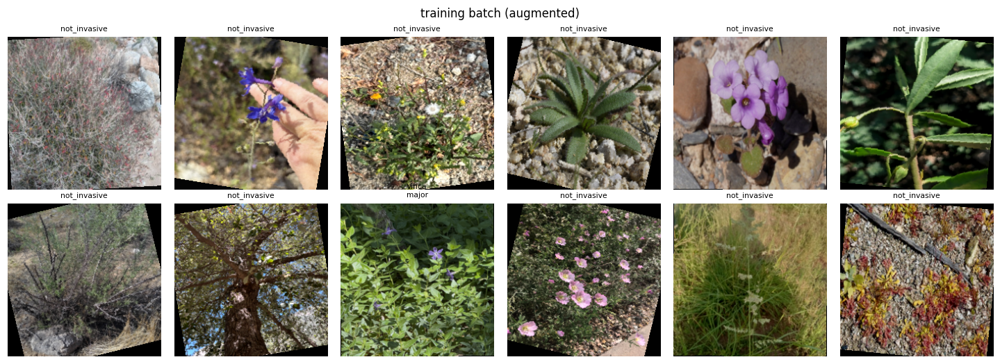

23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 15s | elapsed 0.3m, ~0.5m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0001 | val macro-F1 0.7156 top1 0.8696 mAP 0.7568 t=0.03 | gnorm 0.02 | 13s | elapsed 4.9m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0001 | val macro-F1 0.7147 top1 0.8702 mAP 0.7570 t=0.04 | gnorm 0.02 | 13s | elapsed 5.1m, ~0.0m left in full stage
best epoch 18: macro_f1_invasive 0.7138 | top1_acc_all 0.8690 | macro_ap_invasive 0.7640 | top1_recall_invasive 0.8014 | top3_recall_invasive 0.9257 | bin_precision_invasive 0.8664 | bin_recall_invasive 0.7729 | bin_f1_invasive 0.8170 | bin_ap_invasive 0.9037 | bin_auroc_invasive 0.9451 | noninv_precision 0.9052 | noninv_recall 0.9479 | noninv_auroc 0.9451 | macro_f1_all41 0.7190 | threshold 0.03


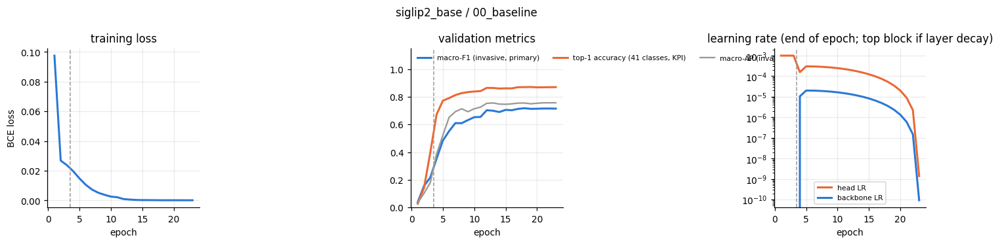

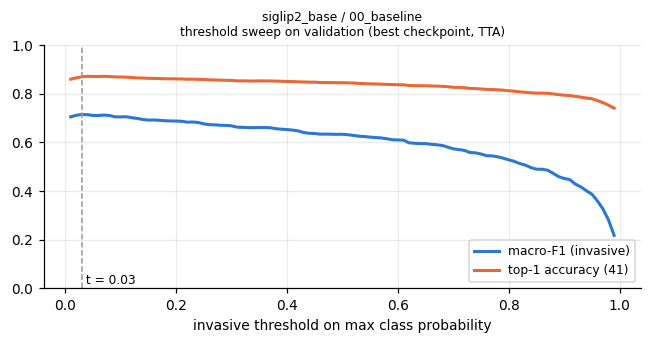

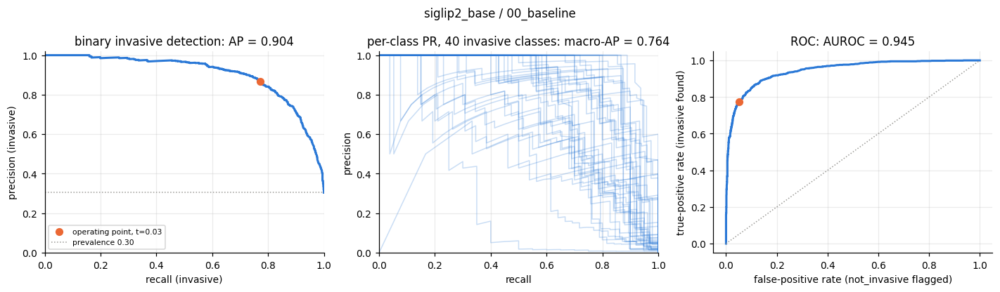

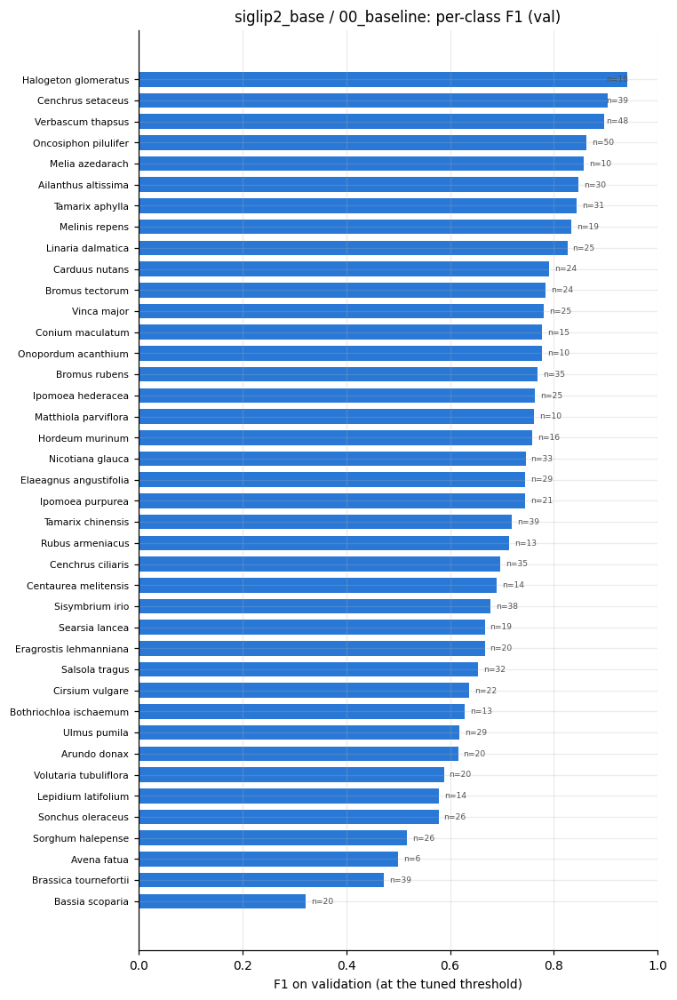

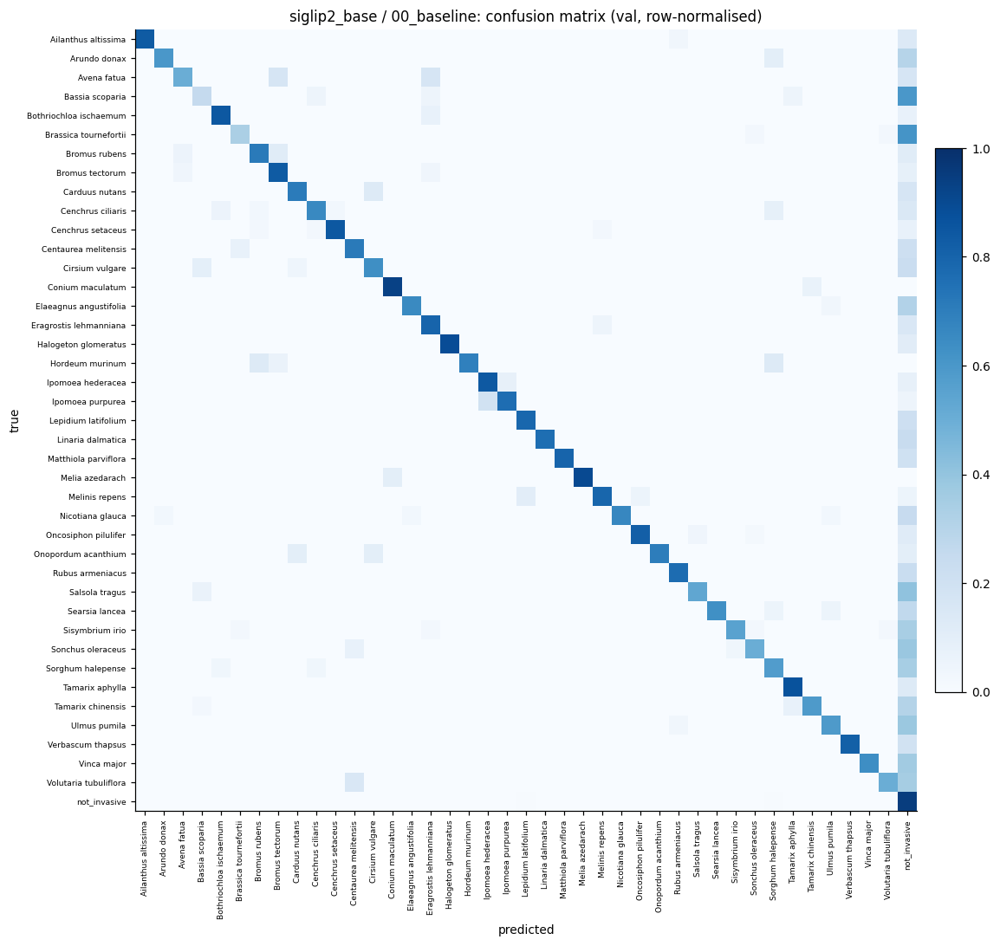

no reference run yet; this run becomes the reference once accepted


{'model': 'siglip2_base',
 'iteration': '00_baseline',
 'best_epoch': 18,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.904885192712148),
 'macro_f1_invasive': 0.713813304901123,
 'top1_acc_all': 0.8689591288566589,
 'macro_ap_invasive': 0.7639860583819974,
 'top1_recall_invasive': 0.8014256619144603,
 'top3_recall_invasive': 0.9256619144602851,
 'threshold': 0.03,
 'bin_precision_invasive': 0.8664383561643836,
 'bin_recall_invasive': 0.7729124236252546,
 'bin_f1_invasive': 0.8170075349838536,
 'bin_ap_invasive': np.float64(0.9037132687429128),
 'bin_auroc_invasive': np.float64(0.9451044899010325),
 'noninv_precision': 0.905187074829932,
 'noninv_recall': 0.9479073909171861,
 'noninv_auroc': np.float64(0.9451044899010325),
 'macro_f1_all41': 0.718989908695221}

In [ ]:
run_iteration("00_baseline", {})

In [ ]:
# Accept this as a reference run that every later iteration is compared with.
accept("00_baseline")

00_baseline: accepted.
siglip2_base: 1 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00


current configuration differs from BASE_CONFIG in: nothing
reference run: 00_baseline


### e.g. 01 - Backbone learning rate

===== siglip2_base / 01a_backbone_lr_1e-5 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/01a_backbone_lr_1e-5
changes vs current configuration: {'backbone_lr': 1e-05}
configuration vs BASE_CONFIG: identical
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 13s | elapsed 0.3m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0002 | val macro-F1 0.7202 top1 0.8736 mAP 0.7707 t=0.10 | gnorm 0.03 | 13s | elapsed 5.2m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0002 | val macro-F1 0.7208 top1 0.8739 mAP 0.7710 t=0.10 | gnorm 0.03 | 13s | elapsed 5.4m, ~0.0m left in full stage
best epoch 15: macro_f1_invasive 0.7334 | top1_acc_all 0.8776 | macro_ap_invasive 0.7757 | top1_recall_invasive 0.8218 | top3_recall_invasive 0.9430 | bin_precision_invasive 0.8859 | bin_recall_invasive 0.7668 | bin_f1_invasive 0.8221 | bin_ap_invasive 0.9135 | bin_auroc_invasive 0.9536 | noninv_precision 0.9037 | noninv_recall 0.9568 | noninv_auroc 0.9536 | macro_f1_all41 0.7382 | threshold 0.06


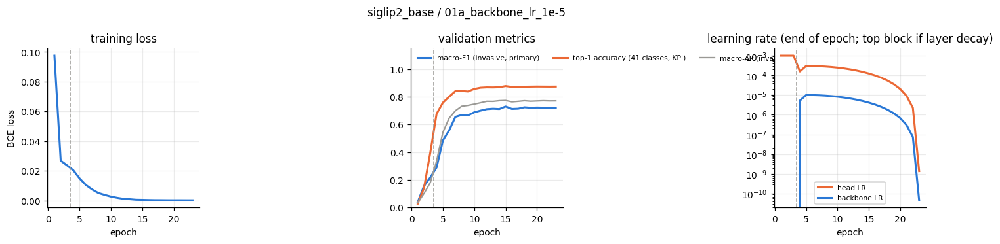

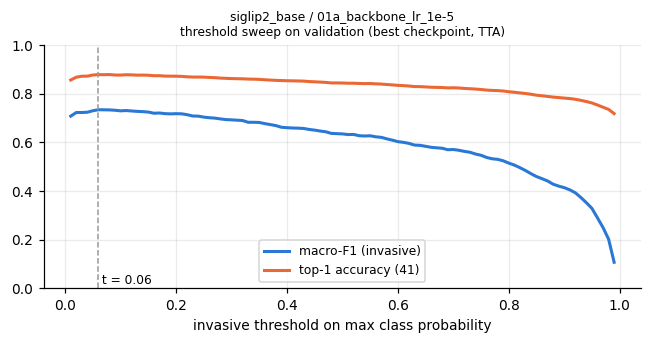

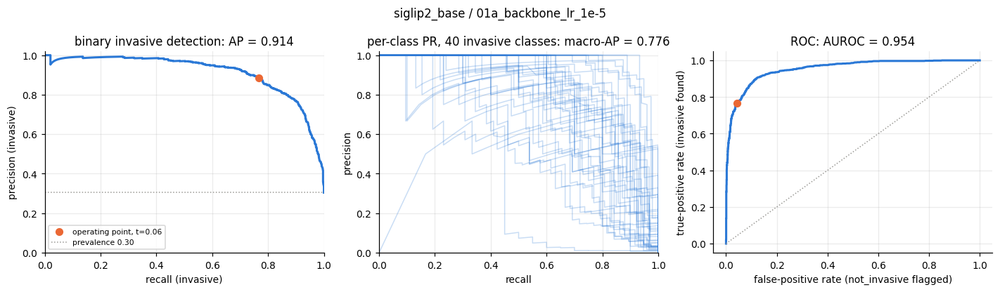

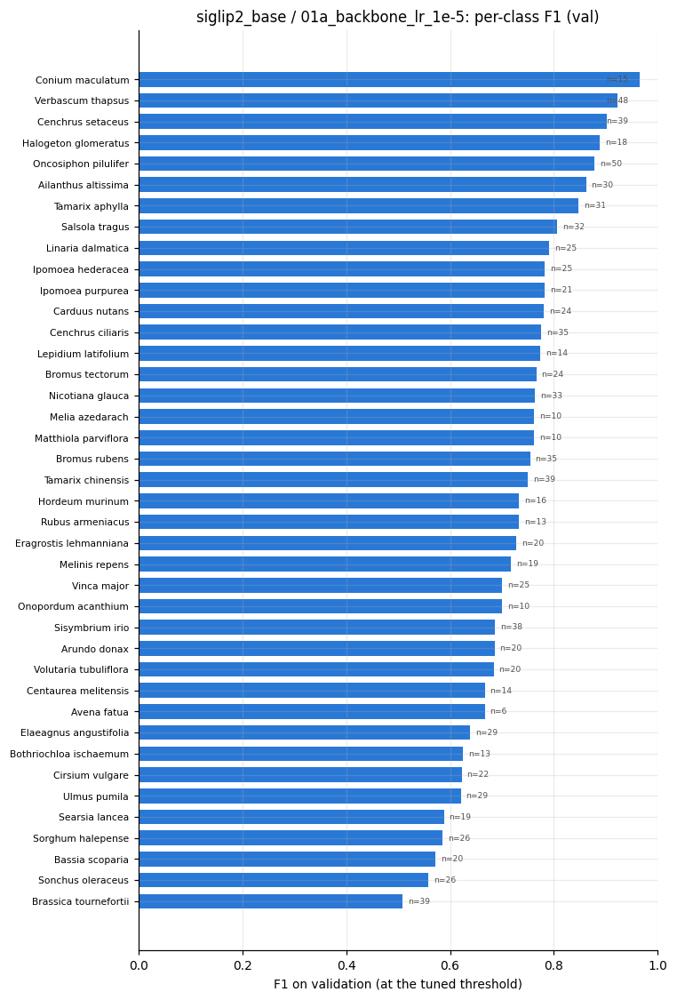

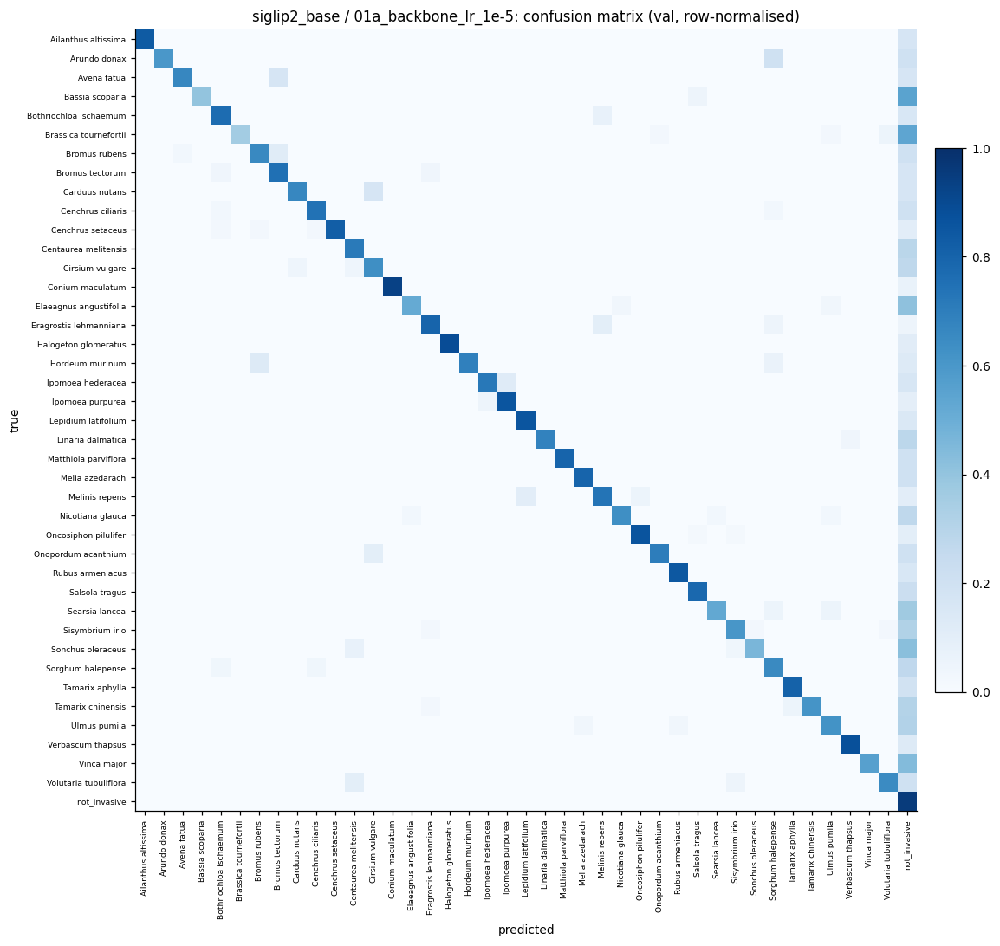

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.8690,0.7640,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 01a_backbone_lr_1e-5,0.7334,0.8776,0.7757,0.8218,0.9430,0.8859,0.7668,0.9536,0.9536,0.06
delta,0.0196,0.0087,0.0118,0.0204,0.0173,0.0194,-0.0061,0.0085,0.0085,0.03


macro-F1 (invasive, primary metric) +0.0196 | top-1 accuracy (KPI) +0.0087. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '01a_backbone_lr_1e-5',
 'best_epoch': 15,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.821088711420695),
 'macro_f1_invasive': 0.7334415912628174,
 'top1_acc_all': 0.8776332139968872,
 'macro_ap_invasive': 0.7757387967357788,
 'top1_recall_invasive': 0.8217922606924644,
 'top3_recall_invasive': 0.9429735234215886,
 'threshold': 0.06,
 'bin_precision_invasive': 0.8858823529411765,
 'bin_recall_invasive': 0.7668024439918534,
 'bin_f1_invasive': 0.8220524017467249,
 'bin_ap_invasive': np.float64(0.9135295661253423),
 'bin_auroc_invasive': np.float64(0.9536217815605204),
 'noninv_precision': 0.9037005887300252,
 'noninv_recall': 0.9568121104185218,
 'noninv_auroc': np.float64(0.9536217815605202),
 'macro_f1_all41': 0.7382234930992126}

In [ ]:
run_iteration("01a_backbone_lr_1e-5", {"backbone_lr": 1e-5})

===== siglip2_base / 01b_backbone_lr_5e-5 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/01b_backbone_lr_5e-5
changes vs current configuration: {'backbone_lr': 5e-05}
configuration vs BASE_CONFIG: identical
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (39 outputs left out)

ep 22/23 [full  ] loss 0.0001 | val macro-F1 0.6327 top1 0.8414 mAP 0.6668 t=0.01 | gnorm 0.01 | 13s | elapsed 5.3m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a18d0ae6520>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a18d0ae6520>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

ep 23/23 [full  ] loss 0.0001 | val macro-F1 0.6345 top1 0.8420 mAP 0.6672 t=0.01 | gnorm 0.01 | 13s | elapsed 5.6m, ~0.0m left in full stage *best*
best epoch 23: macro_f1_invasive 0.6289 | top1_acc_all 0.8420 | macro_ap_invasive 0.6717 | top1_recall_invasive 0.7393 | top3_recall_invasive 0.8880 | bin_precision_invasive 0.8495 | bin_recall_invasive 0.7301 | bin_f1_invasive 0.7853 | bin_ap_invasive 0.8803 | bin_auroc_invasive 0.9289 | noninv_precision 0.8888 | noninv_recall 0.9435 | noninv_auroc 0.9289 | macro_f1_all41 0.6359 | threshold 0.01


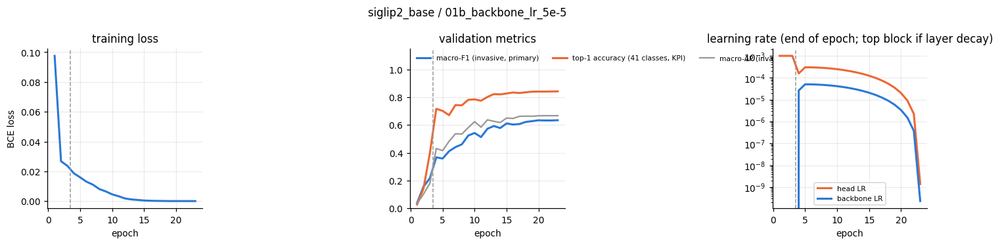

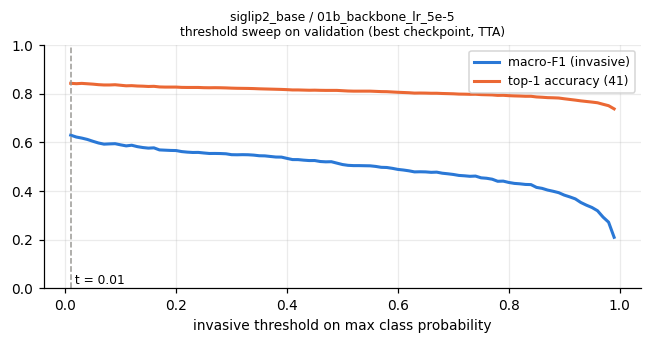

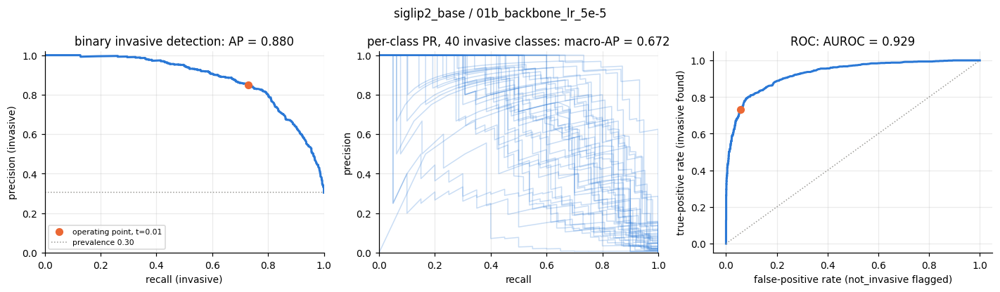

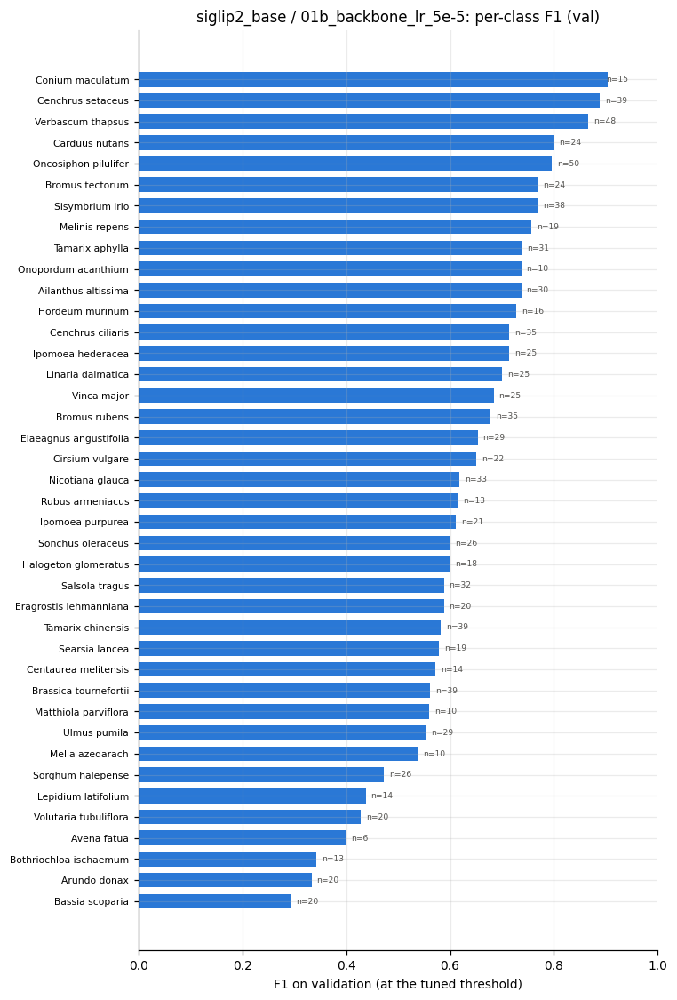

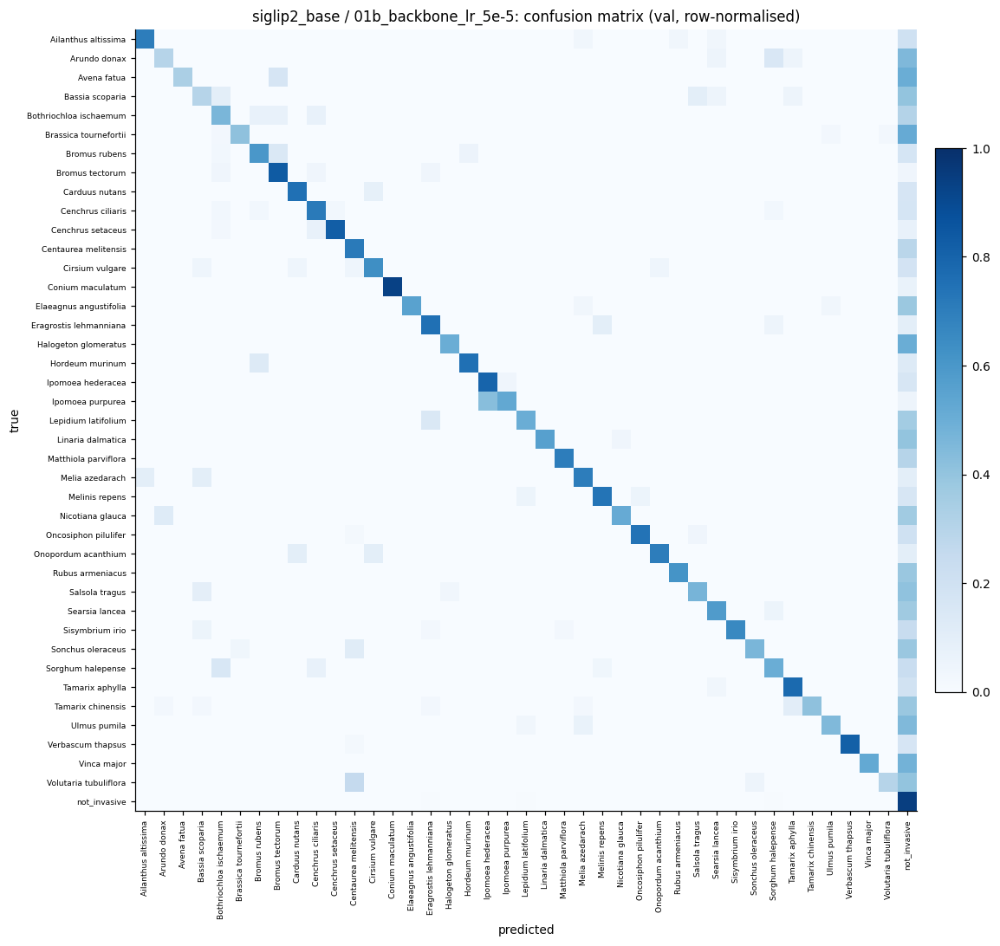

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.869,0.7640,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 01b_backbone_lr_5e-5,0.6289,0.842,0.6717,0.7393,0.8880,0.8495,0.7301,0.9289,0.9289,0.01
delta,-0.0849,-0.027,-0.0923,-0.0621,-0.0377,-0.0169,-0.0428,-0.0162,-0.0162,-0.02


macro-F1 (invasive, primary metric) -0.0849 | top-1 accuracy (KPI) -0.0270. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '01b_backbone_lr_5e-5',
 'best_epoch': 23,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.84608747959137),
 'macro_f1_invasive': 0.6289402842521667,
 'top1_acc_all': 0.8420074582099915,
 'macro_ap_invasive': 0.671735242714443,
 'top1_recall_invasive': 0.7393075356415478,
 'top3_recall_invasive': 0.8879837067209776,
 'threshold': 0.01,
 'bin_precision_invasive': 0.8495260663507109,
 'bin_recall_invasive': 0.730142566191446,
 'bin_f1_invasive': 0.7853231106243155,
 'bin_ap_invasive': np.float64(0.8802634188931258),
 'bin_auroc_invasive': np.float64(0.9288996233176701),
 'noninv_precision': 0.8888422818791947,
 'noninv_recall': 0.9434550311665183,
 'noninv_auroc': np.float64(0.92889962331767),
 'macro_f1_all41': 0.6359255313873291}

In [ ]:
run_iteration("01b_backbone_lr_5e-5", {"backbone_lr": 5e-5})

In [ ]:
# Accept at most ONE of the two; reject the other (or both).
accept("01a_backbone_lr_1e-5", note="macro-F1 (invasive, primary metric) +0.0196 ")
# reject("01a_backbone_lr_1e-5", note="")
# accept("01b_backbone_lr_5e-5", note="")
reject("01b_backbone_lr_5e-5", note="macro-F1 (invasive, primary metric) -0.0849")

01a_backbone_lr_1e-5: accepted. note: macro-F1 (invasive, primary metric) +0.0196 
siglip2_base: 2 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18


current configuration differs from BASE_CONFIG in: {'backbone_lr': 1e-05}
reference run: 01a_backbone_lr_1e-5
01b_backbone_lr_5e-5: rejected. note: macro-F1 (invasive, primary metric) -0.0849
siglip2_base: 3 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18
01b_backbone_lr_5e-5,rejected,"{""backbone_lr"": 5e-05}",0.628940,0.842007,2026-11-04T04:18


current configuration differs from BASE_CONFIG in: {'backbone_lr': 1e-05}
reference run: 01a_backbone_lr_1e-5


### 02 - Layer decay 0.75

===== siglip2_base / 02_layer_decay_0.75 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/02_layer_decay_0.75
changes vs current configuration: {'layer_decay': 0.75}
configuration vs BASE_CONFIG: {'backbone_lr': 1e-05}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 12s | elapsed 0.4m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0009 | val macro-F1 0.7407 top1 0.8798 mAP 0.7869 t=0.16 | gnorm 0.22 | 13s | elapsed 5.4m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0009 | val macro-F1 0.7418 top1 0.8807 mAP 0.7866 t=0.16 | gnorm 0.20 | 13s | elapsed 5.6m, ~0.0m left in full stage
best epoch 20: macro_f1_invasive 0.7476 | top1_acc_all 0.8826 | macro_ap_invasive 0.7908 | top1_recall_invasive 0.8391 | top3_recall_invasive 0.9562 | bin_precision_invasive 0.8820 | bin_recall_invasive 0.7912 | bin_f1_invasive 0.8341 | bin_ap_invasive 0.9203 | bin_auroc_invasive 0.9573 | noninv_precision 0.9127 | noninv_recall 0.9537 | noninv_auroc 0.9573 | macro_f1_all41 0.7521 | threshold 0.11


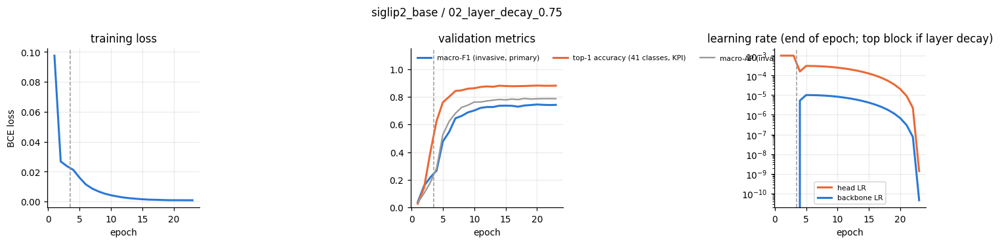

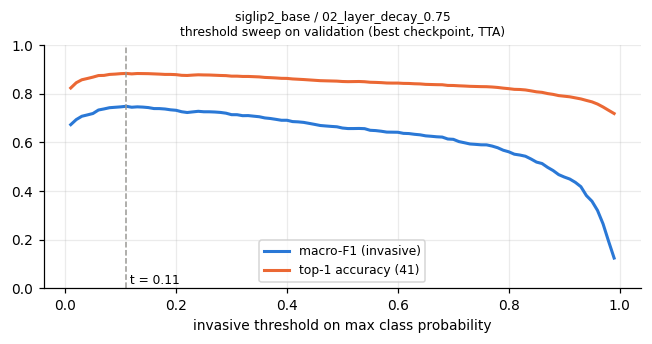

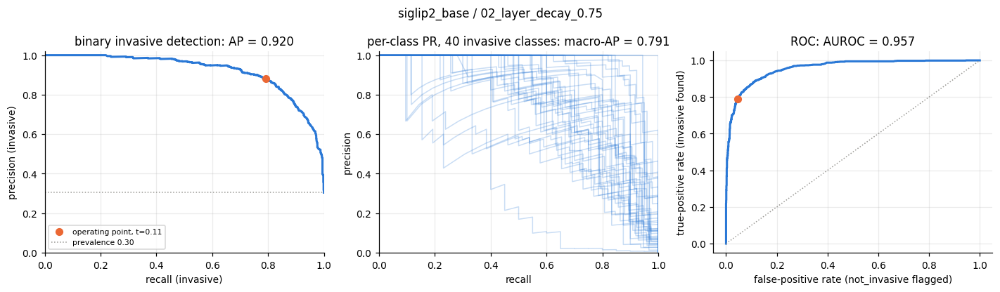

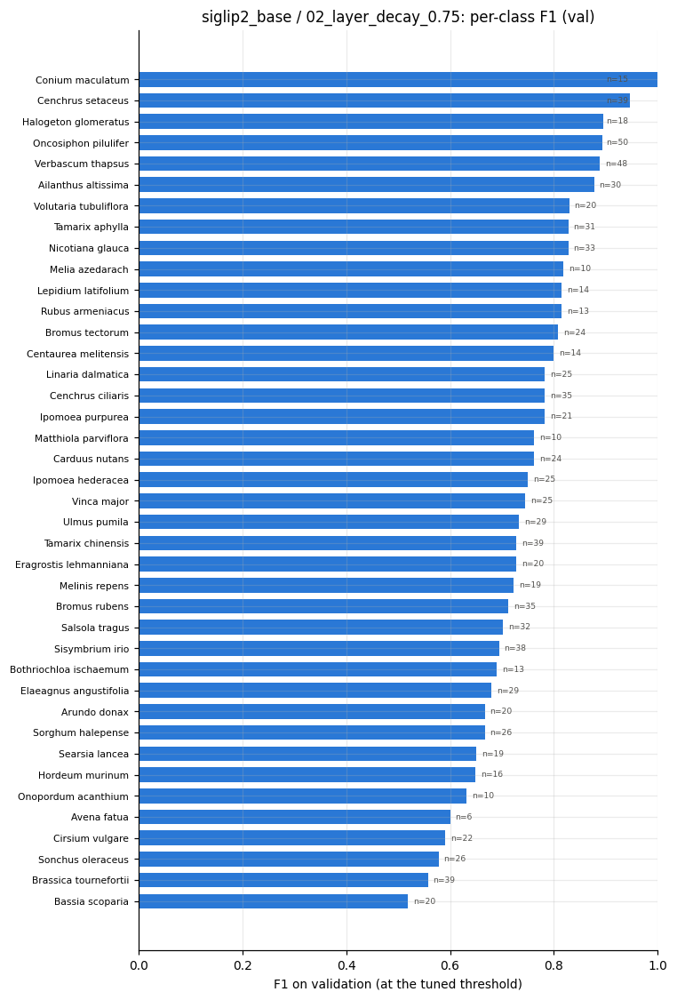

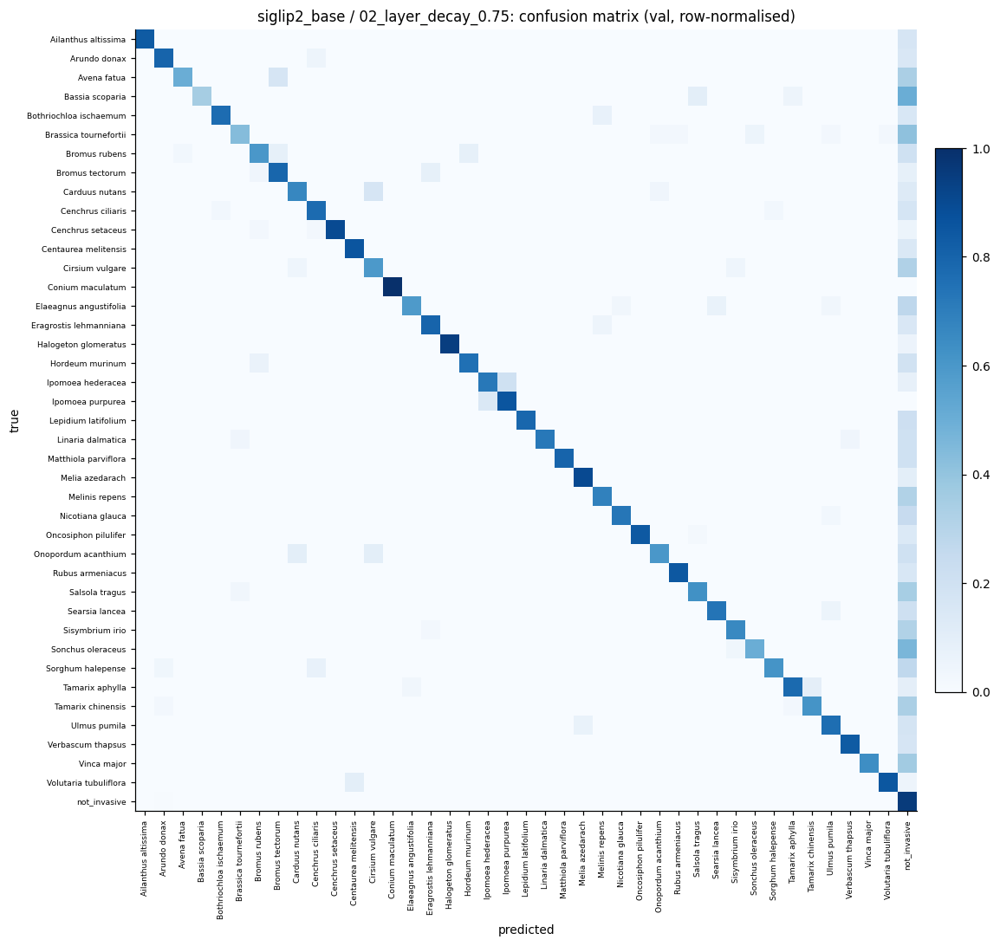

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 01a_backbone_lr_1e-5,0.7334,0.8776,0.7757,0.8218,0.9430,0.8859,0.7668,0.9536,0.9536,0.06
this run: 02_layer_decay_0.75,0.7476,0.8826,0.7908,0.8391,0.9562,0.8820,0.7912,0.9573,0.9573,0.11
delta,0.0142,0.0050,0.0150,0.0173,0.0132,-0.0039,0.0244,0.0037,0.0037,0.05


macro-F1 (invasive, primary metric) +0.0142 | top-1 accuracy (KPI) +0.0050. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '02_layer_decay_0.75',
 'best_epoch': 20,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.81694194873174),
 'macro_f1_invasive': 0.7476022839546204,
 'top1_acc_all': 0.8825898170471191,
 'macro_ap_invasive': 0.7907886277294605,
 'top1_recall_invasive': 0.8391038696537678,
 'top3_recall_invasive': 0.9562118126272913,
 'threshold': 0.11,
 'bin_precision_invasive': 0.8819523269012486,
 'bin_recall_invasive': 0.7912423625254582,
 'bin_f1_invasive': 0.8341384863123994,
 'bin_ap_invasive': np.float64(0.9203282479676667),
 'bin_auroc_invasive': np.float64(0.9573394112729033),
 'noninv_precision': 0.9126544524925436,
 'noninv_recall': 0.9536954585930543,
 'noninv_auroc': np.float64(0.9573394112729033),
 'macro_f1_all41': 0.7521174550056458}

In [ ]:
run_iteration("02_layer_decay_0.75", {"layer_decay": 0.75})

In [ ]:
# Decide after reading the comparison above; run ONE line:
accept("02_layer_decay_0.75", note="macro-F1 (invasive, primary metric) +0.0142")
# reject("02_layer_decay_0.75", note="")

02_layer_decay_0.75: accepted. note: macro-F1 (invasive, primary metric) +0.0142
siglip2_base: 4 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18
01b_backbone_lr_5e-5,rejected,"{""backbone_lr"": 5e-05}",0.628940,0.842007,2026-11-04T04:18
02_layer_decay_0.75,accepted,"{""layer_decay"": 0.75}",0.747602,0.882590,2026-11-04T04:25


current configuration differs from BASE_CONFIG in: {'backbone_lr': 1e-05, 'layer_decay': 0.75}
reference run: 02_layer_decay_0.75


### 02r — Backbone LR after layer decay (only if 02 was accepted; otherwise skip)

===== siglip2_base / 02r_backbone_lr_2e-5 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/02r_backbone_lr_2e-5
changes vs current configuration: {'backbone_lr': 2e-05}
configuration vs BASE_CONFIG: {'backbone_lr': 1e-05, 'layer_decay': 0.75}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 13s | elapsed 0.4m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0002 | val macro-F1 0.7496 top1 0.8872 mAP 0.8027 t=0.09 | gnorm 0.08 | 13s | elapsed 5.2m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0002 | val macro-F1 0.7485 top1 0.8866 mAP 0.8029 t=0.09 | gnorm 0.07 | 13s | elapsed 5.5m, ~0.0m left in full stage
best epoch 20: macro_f1_invasive 0.7592 | top1_acc_all 0.8894 | macro_ap_invasive 0.8072 | top1_recall_invasive 0.8391 | top3_recall_invasive 0.9562 | bin_precision_invasive 0.8987 | bin_recall_invasive 0.7953 | bin_f1_invasive 0.8439 | bin_ap_invasive 0.9244 | bin_auroc_invasive 0.9591 | noninv_precision 0.9148 | noninv_recall 0.9608 | noninv_auroc 0.9591 | macro_f1_all41 0.7636 | threshold 0.07


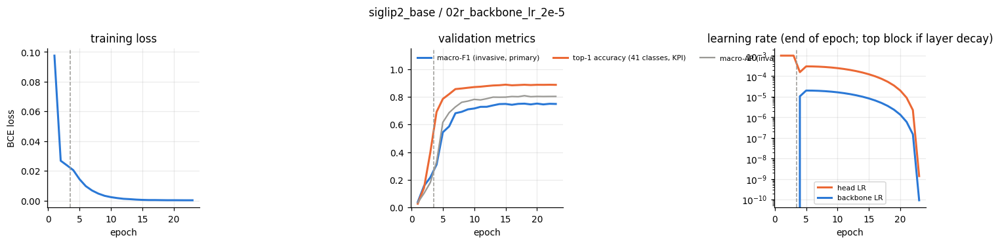

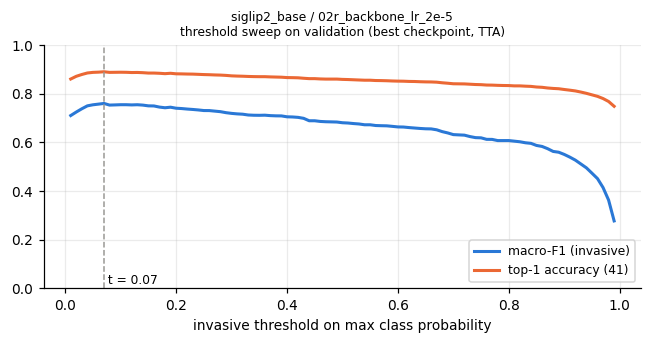

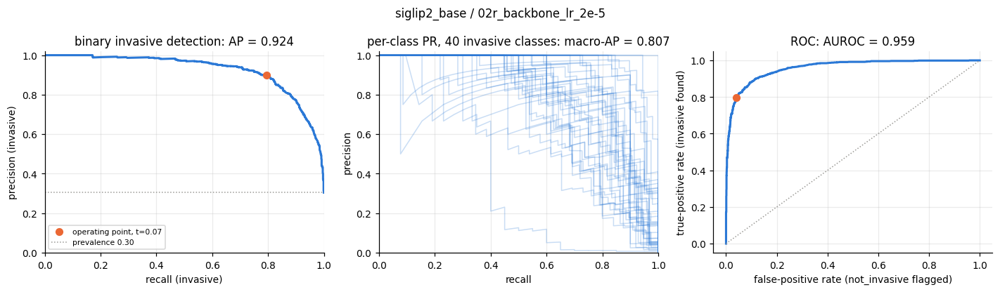

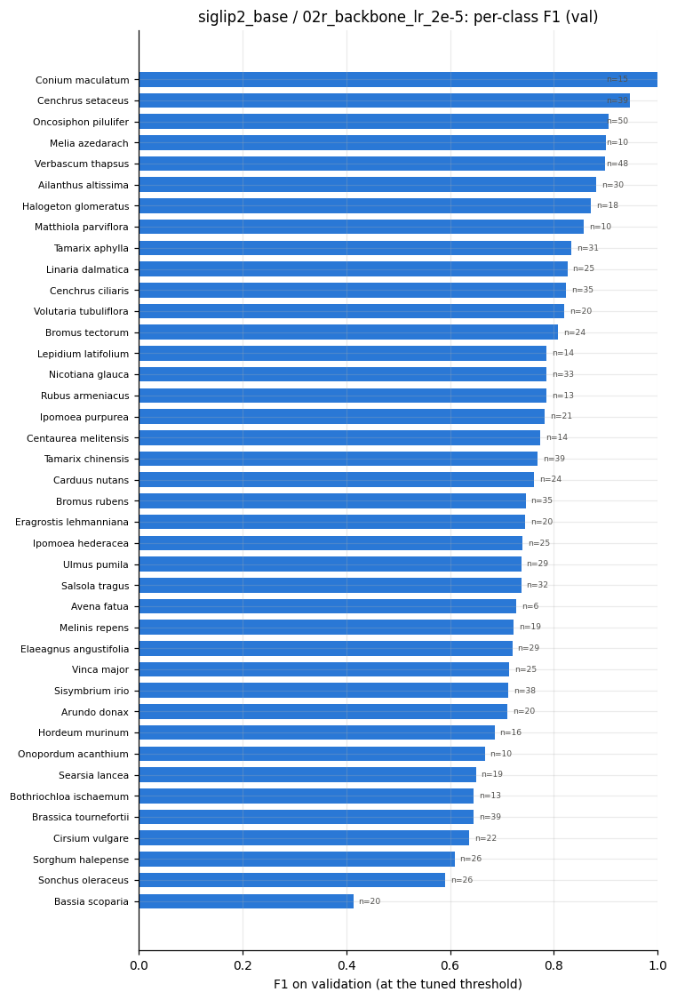

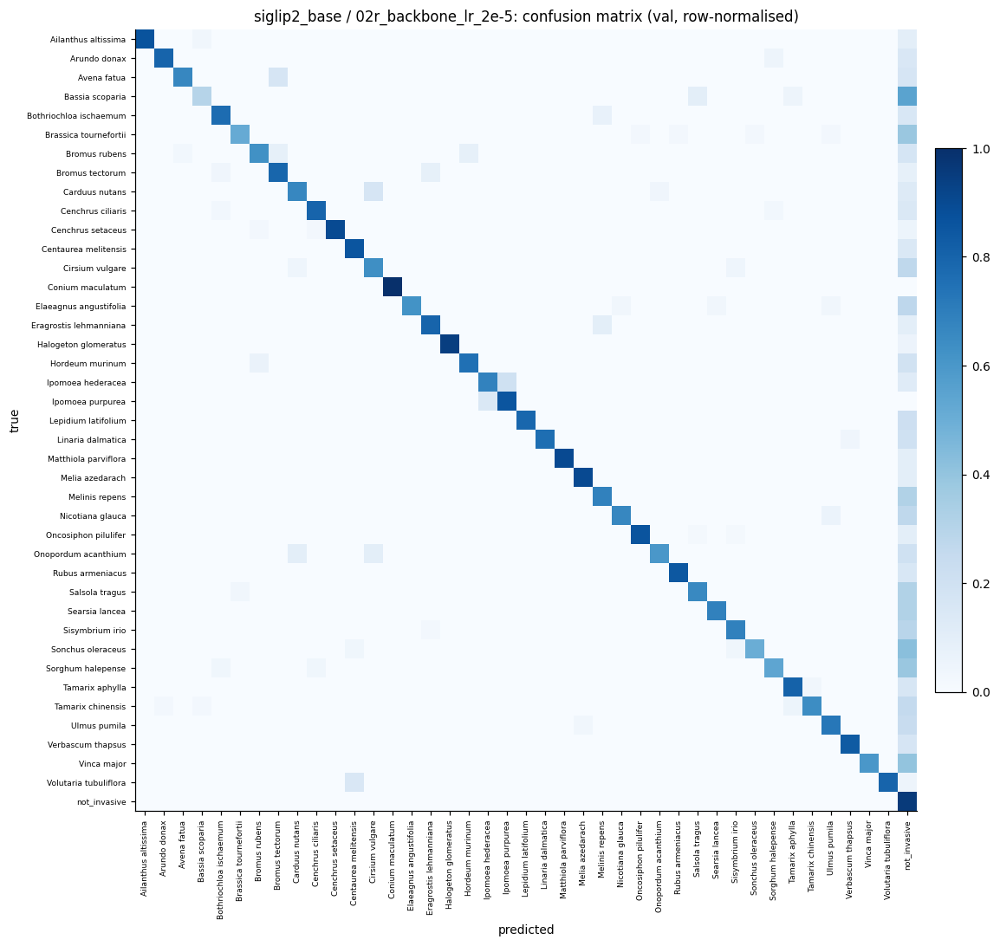

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 02_layer_decay_0.75,0.7476,0.8826,0.7908,0.8391,0.9562,0.8820,0.7912,0.9573,0.9573,0.11
this run: 02r_backbone_lr_2e-5,0.7592,0.8894,0.8072,0.8391,0.9562,0.8987,0.7953,0.9591,0.9591,0.07
delta,0.0116,0.0068,0.0164,0.0000,0.0000,0.0168,0.0041,0.0018,0.0018,-0.04


macro-F1 (invasive, primary metric) +0.0116 | top-1 accuracy (KPI) +0.0068. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '02r_backbone_lr_2e-5',
 'best_epoch': 20,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.842046761512757),
 'macro_f1_invasive': 0.7592471241950989,
 'top1_acc_all': 0.8894051909446716,
 'macro_ap_invasive': 0.8071676252911926,
 'top1_recall_invasive': 0.8391038696537678,
 'top3_recall_invasive': 0.9562118126272913,
 'threshold': 0.07,
 'bin_precision_invasive': 0.8987341772151899,
 'bin_recall_invasive': 0.7953156822810591,
 'bin_f1_invasive': 0.8438681793625068,
 'bin_ap_invasive': np.float64(0.9243914213230289),
 'bin_auroc_invasive': np.float64(0.9590976853170063),
 'noninv_precision': 0.9147944044086477,
 'noninv_recall': 0.9608192341941229,
 'noninv_auroc': np.float64(0.9590976853170061),
 'macro_f1_all41': 0.7635884881019592}

In [ ]:
# Double the current backbone LR. Uncomment the ONE line that matches what you accepted in 01:
# run_iteration("02r_backbone_lr_4e-5", {"backbone_lr": 4e-5})    # 01: neither accepted (current 2e-5)
run_iteration("02r_backbone_lr_2e-5", {"backbone_lr": 2e-5})    # 01a accepted (current 1e-5)
# run_iteration("02r_backbone_lr_1e-4", {"backbone_lr": 1e-4})    # 01b accepted (current 5e-5)

In [ ]:
# Decide after reading the comparison above; run ONE line:
accept("02r_backbone_lr_2e-5", note="macro-F1 (invasive, primary metric) +0.0116")
# reject("02r_backbone_lr_XXX", note="")

02r_backbone_lr_2e-5: accepted. note: macro-F1 (invasive, primary metric) +0.0116
siglip2_base: 5 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18
01b_backbone_lr_5e-5,rejected,"{""backbone_lr"": 5e-05}",0.628940,0.842007,2026-11-04T04:18
02_layer_decay_0.75,accepted,"{""layer_decay"": 0.75}",0.747602,0.882590,2026-11-04T04:25
02r_backbone_lr_2e-5,accepted,"{""backbone_lr"": 2e-05}",0.759247,0.889405,2026-11-04T04:34


current configuration differs from BASE_CONFIG in: {'layer_decay': 0.75}
reference run: 02r_backbone_lr_2e-5


### e.g. 03 — Longer frozen stage

===== siglip2_base / 03_frozen_epochs_8 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/03_frozen_epochs_8
changes vs current configuration: {'frozen_epochs': 8}
configuration vs BASE_CONFIG: {'layer_decay': 0.75}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
28 epochs (8 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/28 [frozen] loss 0.0975 | val macro-F1 0.0389 top1 0.0273 mAP 0.0341 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~1.5m left in frozen stage + full stage *best*


epoch 2/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/28 [frozen] loss 0.0268 | val macro-F1 0.1557 top1 0.1419 mAP 0.1021 t=0.01 | gnorm 0.02 | 13s | elapsed 0.4m, ~1.3m left in frozen stage + full stage *best*


epoch 3/28 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (50 outputs left out)

epoch 27/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 27/28 [full  ] loss 0.0002 | val macro-F1 0.7480 top1 0.8854 mAP 0.8001 t=0.07 | gnorm 0.08 | 13s | elapsed 6.8m, ~0.2m left in full stage


epoch 28/28 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 28/28 [full  ] loss 0.0002 | val macro-F1 0.7471 top1 0.8851 mAP 0.8002 t=0.07 | gnorm 0.10 | 13s | elapsed 7.0m, ~0.0m left in full stage
best epoch 22: macro_f1_invasive 0.7555 | top1_acc_all 0.8894 | macro_ap_invasive 0.8050 | top1_recall_invasive 0.8442 | top3_recall_invasive 0.9511 | bin_precision_invasive 0.9115 | bin_recall_invasive 0.7760 | bin_f1_invasive 0.8383 | bin_ap_invasive 0.9297 | bin_auroc_invasive 0.9629 | noninv_precision 0.9080 | noninv_recall 0.9671 | noninv_auroc 0.9629 | macro_f1_all41 0.7599 | threshold 0.11


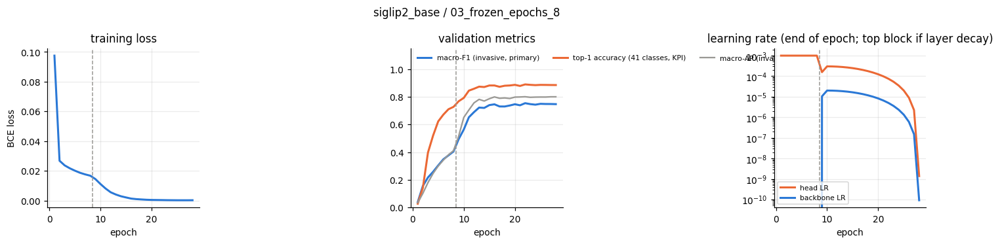

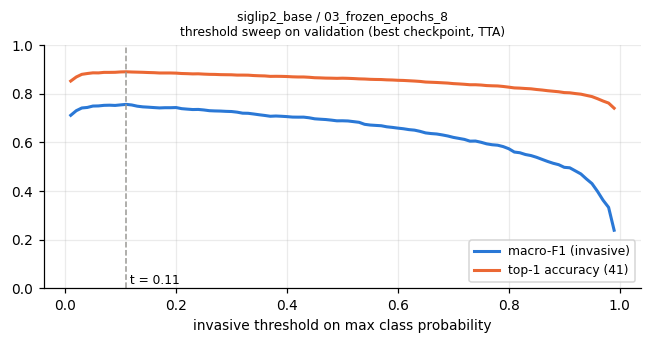

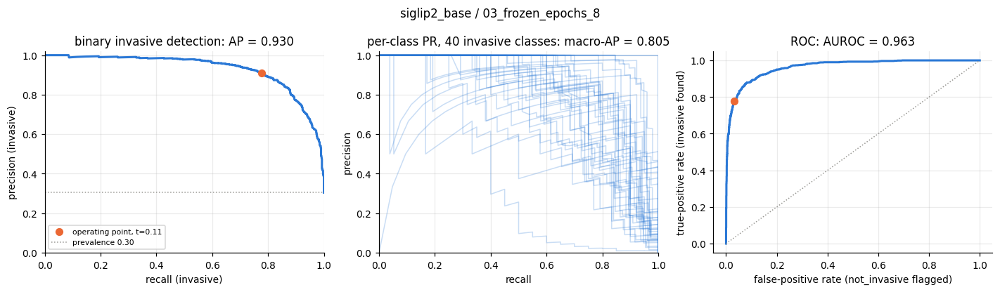

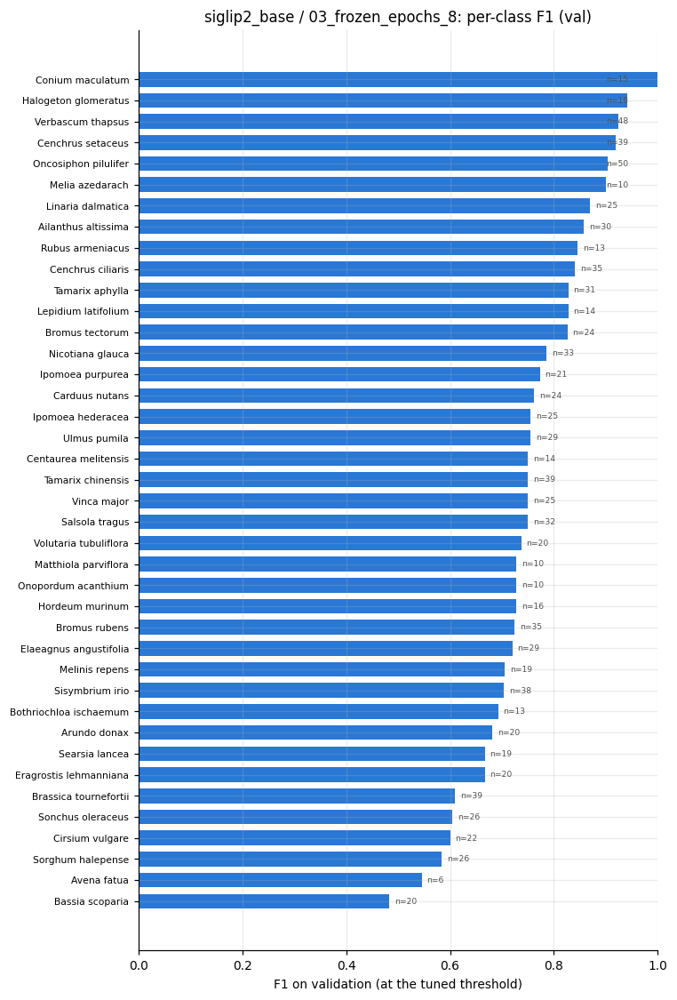

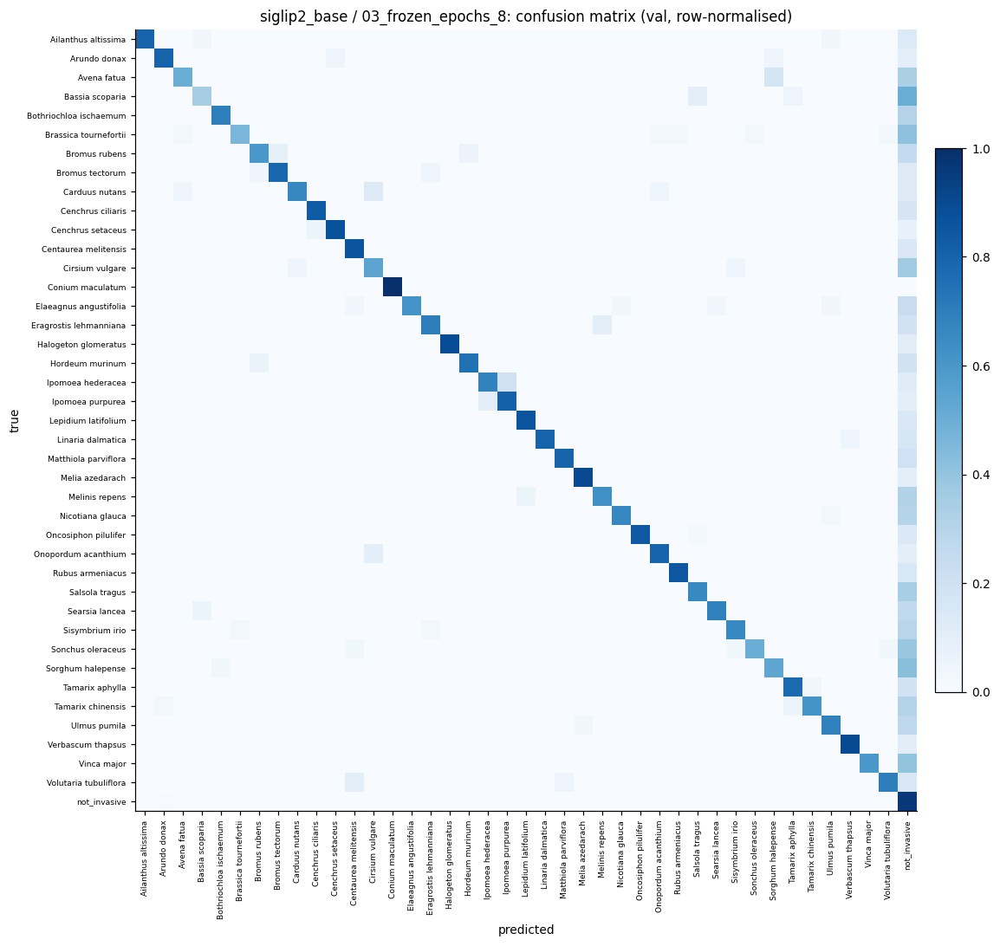

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 02r_backbone_lr_2e-5,0.7592,0.8894,0.8072,0.8391,0.9562,0.8987,0.7953,0.9591,0.9591,0.07
this run: 03_frozen_epochs_8,0.7555,0.8894,0.8050,0.8442,0.9511,0.9115,0.7760,0.9629,0.9629,0.11
delta,-0.0038,0.0000,-0.0021,0.0051,-0.0051,0.0127,-0.0193,0.0038,0.0038,0.04


macro-F1 (invasive, primary metric) -0.0038 | top-1 accuracy (KPI) +0.0000. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '03_frozen_epochs_8',
 'best_epoch': 22,
 'epochs': 28,
 'tta_hflip': True,
 'train_minutes': np.float64(5.973905670642853),
 'macro_f1_invasive': 0.7554783821105957,
 'top1_acc_all': 0.8894051909446716,
 'macro_ap_invasive': 0.8050318521435738,
 'top1_recall_invasive': 0.8441955193482689,
 'top3_recall_invasive': 0.9511201629327902,
 'threshold': 0.11,
 'bin_precision_invasive': 0.9114832535885168,
 'bin_recall_invasive': 0.7759674134419552,
 'bin_f1_invasive': 0.8382838283828383,
 'bin_ap_invasive': np.float64(0.9296670418021947),
 'bin_auroc_invasive': np.float64(0.9629175560806903),
 'noninv_precision': 0.9080267558528428,
 'noninv_recall': 0.9670525378450578,
 'noninv_auroc': np.float64(0.9629175560806902),
 'macro_f1_all41': 0.7598962783813477}

In [ ]:
run_iteration("03_frozen_epochs_8", {"frozen_epochs": 8})

In [ ]:
# Decide after reading the comparison above; run ONE line:
# accept("03_frozen_epochs_8", note="")
reject("03_frozen_epochs_8", note="macro-F1 (invasive, primary metric) -0.0038 ")

03_frozen_epochs_8: rejected. note: macro-F1 (invasive, primary metric) -0.0038 
siglip2_base: 6 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18
01b_backbone_lr_5e-5,rejected,"{""backbone_lr"": 5e-05}",0.628940,0.842007,2026-11-04T04:18
02_layer_decay_0.75,accepted,"{""layer_decay"": 0.75}",0.747602,0.882590,2026-11-04T04:25
02r_backbone_lr_2e-5,accepted,"{""backbone_lr"": 2e-05}",0.759247,0.889405,2026-11-04T04:34
03_frozen_epochs_8,rejected,"{""frozen_epochs"": 8}",0.755478,0.889405,2026-11-04T04:43


current configuration differs from BASE_CONFIG in: {'layer_decay': 0.75}
reference run: 02r_backbone_lr_2e-5


### 04 - Weight decay

===== siglip2_base / 04_weight_decay_0.05 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/04_weight_decay_0.05
changes vs current configuration: {'weight_decay': 0.05}
configuration vs BASE_CONFIG: {'layer_decay': 0.75}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0976 | val macro-F1 0.0382 top1 0.0273 mAP 0.0344 t=0.01 | gnorm 0.12 | 13s | elapsed 0.3m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0269 | val macro-F1 0.1568 top1 0.1413 mAP 0.1018 t=0.01 | gnorm 0.02 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0002 | val macro-F1 0.7447 top1 0.8851 mAP 0.8007 t=0.10 | gnorm 0.08 | 13s | elapsed 5.3m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0002 | val macro-F1 0.7455 top1 0.8854 mAP 0.8014 t=0.09 | gnorm 0.07 | 13s | elapsed 5.5m, ~0.0m left in full stage
best epoch 18: macro_f1_invasive 0.7622 | top1_acc_all 0.8897 | macro_ap_invasive 0.8111 | top1_recall_invasive 0.8513 | top3_recall_invasive 0.9521 | bin_precision_invasive 0.8886 | bin_recall_invasive 0.8045 | bin_f1_invasive 0.8445 | bin_ap_invasive 0.9233 | bin_auroc_invasive 0.9587 | noninv_precision 0.9179 | noninv_recall 0.9559 | noninv_auroc 0.9587 | macro_f1_all41 0.7665 | threshold 0.07


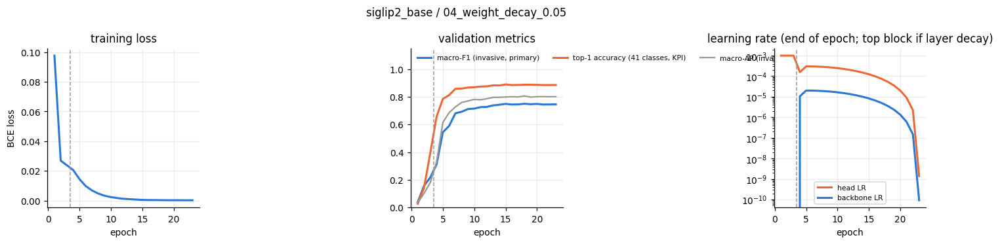

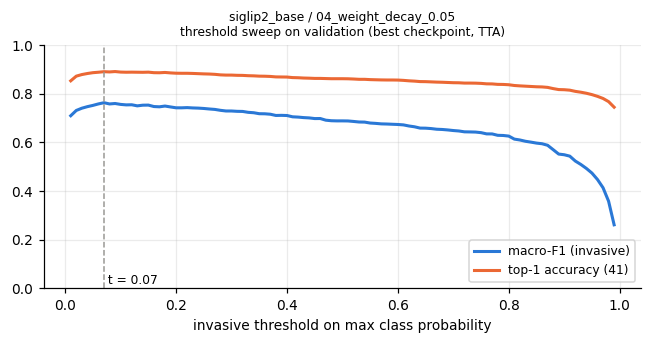

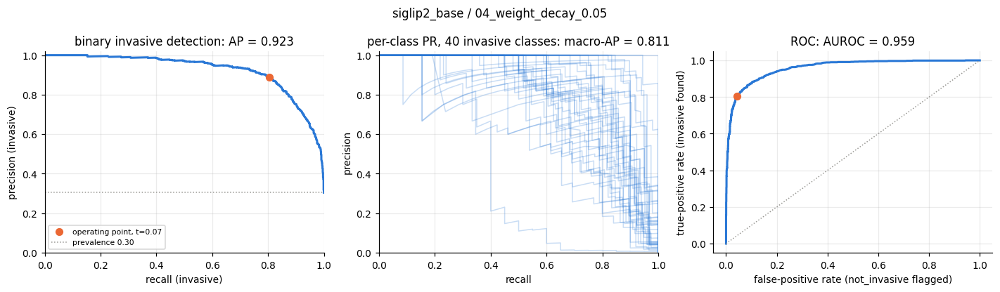

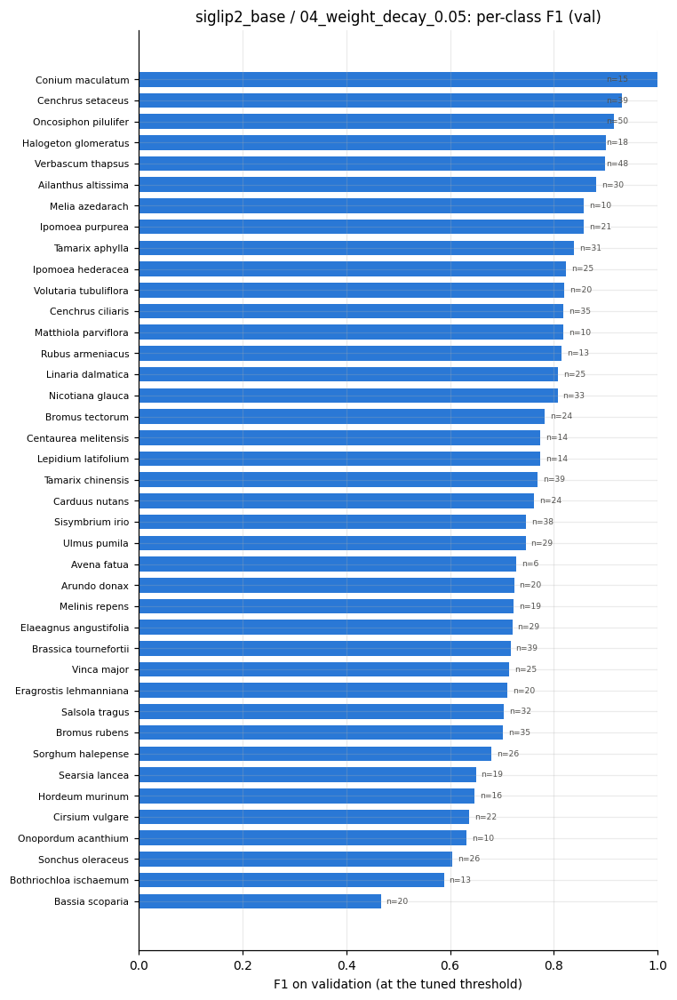

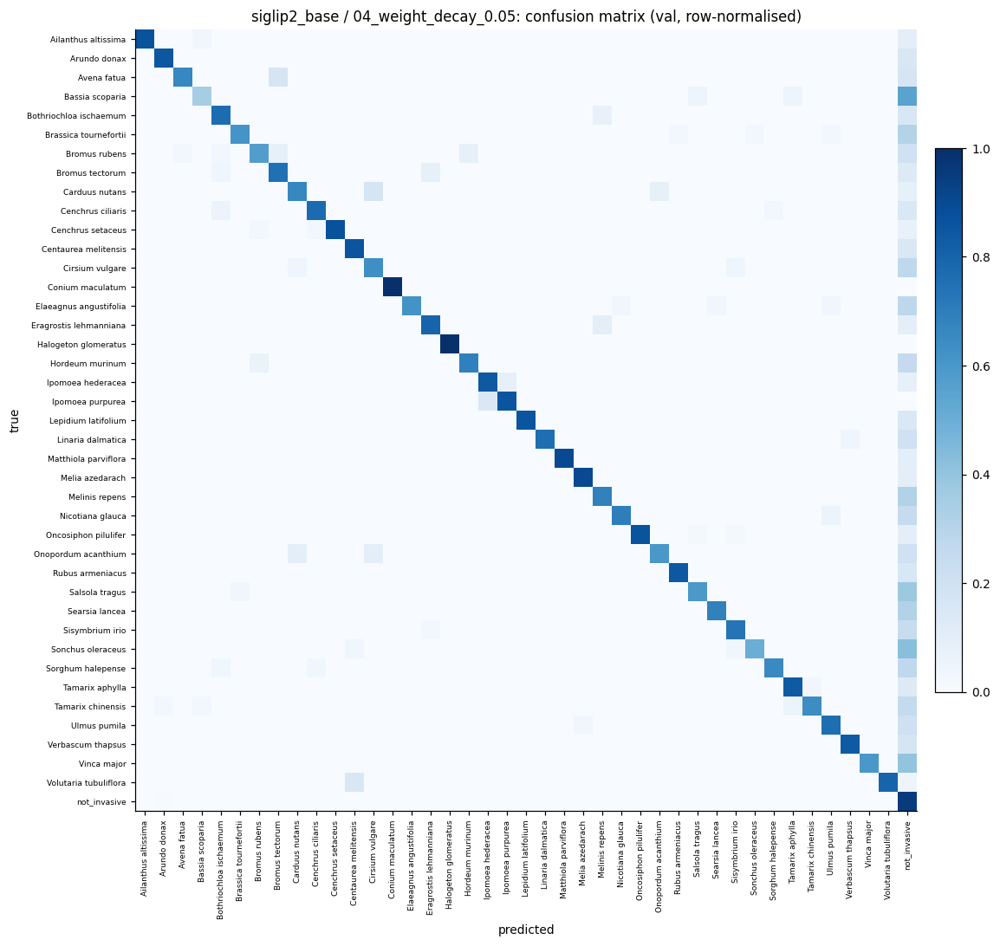

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 02r_backbone_lr_2e-5,0.7592,0.8894,0.8072,0.8391,0.9562,0.8987,0.7953,0.9591,0.9591,0.07
this run: 04_weight_decay_0.05,0.7622,0.8897,0.8111,0.8513,0.9521,0.8886,0.8045,0.9587,0.9587,0.07
delta,0.0030,0.0003,0.0040,0.0122,-0.0041,-0.0101,0.0092,-0.0004,-0.0004,0.00


macro-F1 (invasive, primary metric) +0.0030 | top-1 accuracy (KPI) +0.0003. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '04_weight_decay_0.05',
 'best_epoch': 18,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.8209317048390705),
 'macro_f1_invasive': 0.7622416019439697,
 'top1_acc_all': 0.8897150158882141,
 'macro_ap_invasive': 0.8111276570689114,
 'top1_recall_invasive': 0.8513238289205702,
 'top3_recall_invasive': 0.9521384928716904,
 'threshold': 0.07,
 'bin_precision_invasive': 0.8886389201349831,
 'bin_recall_invasive': 0.8044806517311609,
 'bin_f1_invasive': 0.8444681988241582,
 'bin_ap_invasive': np.float64(0.9233484572318678),
 'bin_auroc_invasive': np.float64(0.9586837337434462),
 'noninv_precision': 0.9179136383069688,
 'noninv_recall': 0.9559216384683883,
 'noninv_auroc': np.float64(0.9586837337434462),
 'macro_f1_all41': 0.7664926052093506}

In [ ]:
run_iteration("04_weight_decay_0.05", {"weight_decay": 0.05})

In [ ]:
accept("04_weight_decay_0.05", note="macro-F1 (invasive, primary metric) +0.0030 ")
# reject("04_weight_decay_0.05", note="")

04_weight_decay_0.05: accepted. note: macro-F1 (invasive, primary metric) +0.0030 
siglip2_base: 7 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
01a_backbone_lr_1e-5,accepted,"{""backbone_lr"": 1e-05}",0.733442,0.877633,2026-11-04T04:18
01b_backbone_lr_5e-5,rejected,"{""backbone_lr"": 5e-05}",0.628940,0.842007,2026-11-04T04:18
02_layer_decay_0.75,accepted,"{""layer_decay"": 0.75}",0.747602,0.882590,2026-11-04T04:25
02r_backbone_lr_2e-5,accepted,"{""backbone_lr"": 2e-05}",0.759247,0.889405,2026-11-04T04:34
03_frozen_epochs_8,rejected,"{""frozen_epochs"": 8}",0.755478,0.889405,2026-11-04T04:43
04_weight_decay_0.05,accepted,"{""weight_decay"": 0.05}",0.762242,0.889715,2026-11-04T04:51


current configuration differs from BASE_CONFIG in: {'weight_decay': 0.05, 'layer_decay': 0.75}
reference run: 04_weight_decay_0.05


### 05 - Stochastic depth 0.1

===== siglip2_base / 05_drop_path_0.1 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/05_drop_path_0.1
changes vs current configuration: {'backbone_kwargs': {'drop_path_rate': 0.1}}
configuration vs BASE_CONFIG: identical


model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.1
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9644ae6520>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9644ae6520>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (43 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0018 | val macro-F1 0.6997 top1 0.8680 mAP 0.7421 t=0.20 | gnorm 0.15 | 13s | elapsed 5.0m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0018 | val macro-F1 0.6994 top1 0.8674 mAP 0.7417 t=0.21 | gnorm 0.16 | 13s | elapsed 5.3m, ~0.0m left in full stage
best epoch 21: macro_f1_invasive 0.7040 | top1_acc_all 0.8652 | macro_ap_invasive 0.7483 | top1_recall_invasive 0.8167 | top3_recall_invasive 0.9318 | bin_precision_invasive 0.8585 | bin_recall_invasive 0.7597 | bin_f1_invasive 0.8061 | bin_ap_invasive 0.9009 | bin_auroc_invasive 0.9436 | noninv_precision 0.9000 | noninv_recall 0.9452 | noninv_auroc 0.9436 | macro_f1_all41 0.7093 | threshold 0.11


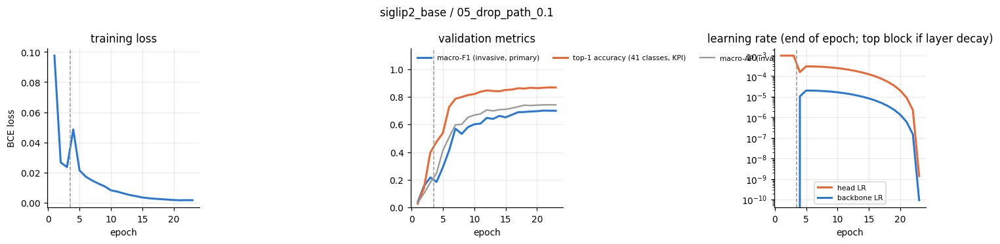

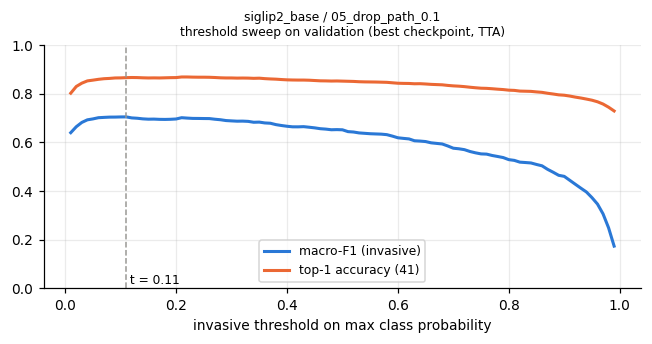

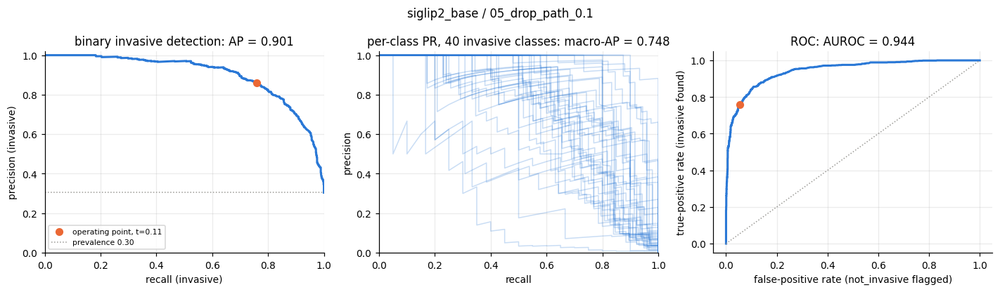

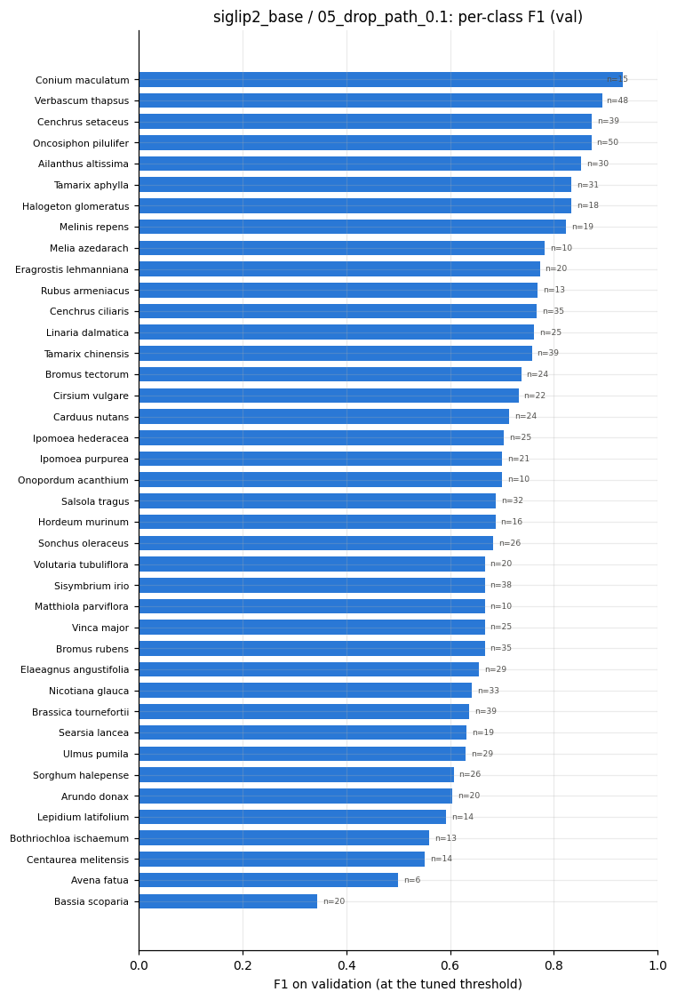

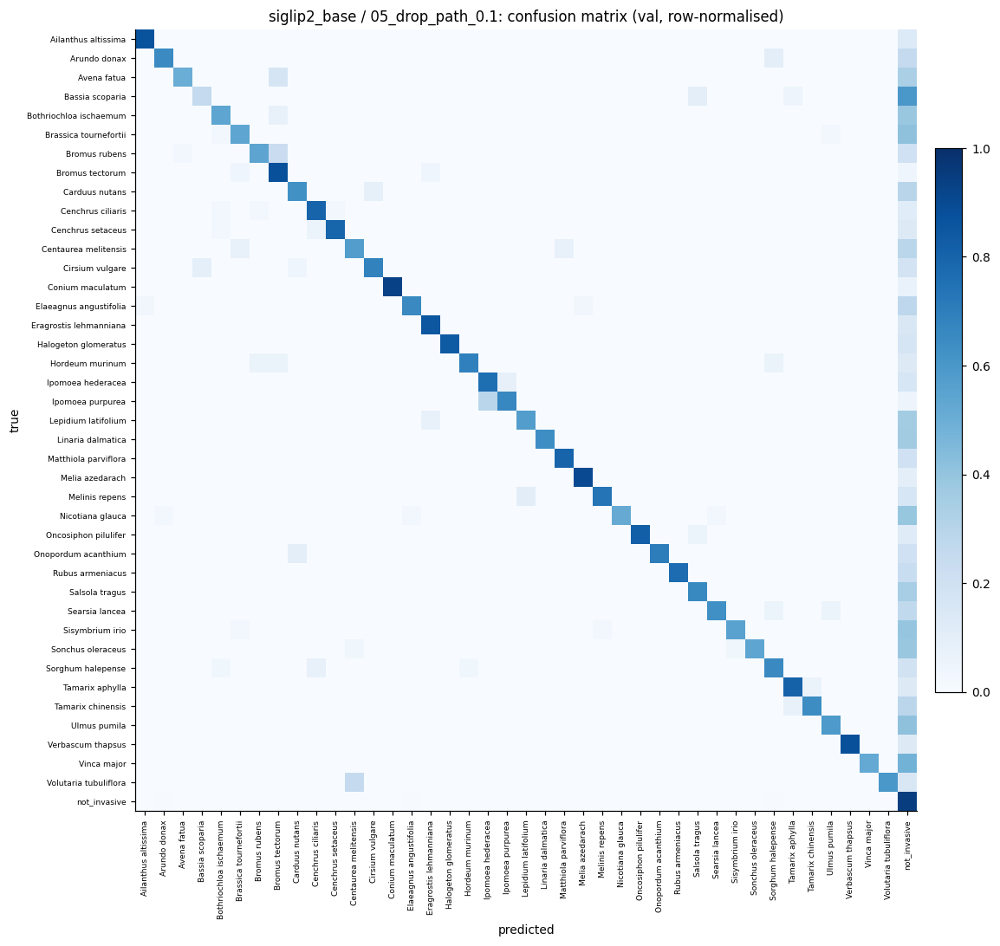

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.8690,0.7640,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 05_drop_path_0.1,0.7040,0.8652,0.7483,0.8167,0.9318,0.8585,0.7597,0.9436,0.9436,0.11
delta,-0.0098,-0.0037,-0.0156,0.0153,0.0061,-0.0080,-0.0132,-0.0015,-0.0015,0.08


macro-F1 (invasive, primary metric) -0.0098 | top-1 accuracy (KPI) -0.0037. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '05_drop_path_0.1',
 'best_epoch': 21,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.879435273011525),
 'macro_f1_invasive': 0.7040093541145325,
 'top1_acc_all': 0.8652416467666626,
 'macro_ap_invasive': 0.7483467944998627,
 'top1_recall_invasive': 0.8167006109979633,
 'top3_recall_invasive': 0.9317718940936863,
 'threshold': 0.11,
 'bin_precision_invasive': 0.8584579976985041,
 'bin_recall_invasive': 0.7596741344195519,
 'bin_f1_invasive': 0.8060507833603457,
 'bin_ap_invasive': np.float64(0.9009483133492064),
 'bin_auroc_invasive': np.float64(0.9435681537487781),
 'noninv_precision': 0.8999576091564222,
 'noninv_recall': 0.9452359750667854,
 'noninv_auroc': np.float64(0.9435681537487782),
 'macro_f1_all41': 0.7093271613121033}

In [ ]:
run_iteration("05_drop_path_0.1", {"backbone_kwargs": {"drop_path_rate": 0.1}})

In [ ]:
# accept("05_drop_path_0.1", note="")
reject("05_drop_path_0.1", note="macro-F1 (invasive, primary metric) -0.0098")

05_drop_path_0.1: rejected. note: macro-F1 (invasive, primary metric) -0.0098
siglip2_base: 2 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49


current configuration differs from BASE_CONFIG in: nothing
reference run: 00_baseline


### 06 - MixUp 0.2 + label smoothing 0.05

===== siglip2_base / 06_mixup0.2_ls0.05 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/06_mixup0.2_ls0.05
changes vs current configuration: {'mixup_alpha': 0.2, 'label_smoothing': 0.05}
configuration vs BASE_CONFIG: identical
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.1814 | val macro-F1 0.0430 top1 0.2831 mAP 0.0364 t=0.07 | gnorm 0.10 | 13s | elapsed 0.3m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.1326 | val macro-F1 0.1330 top1 0.4027 mAP 0.1138 t=0.08 | gnorm 0.02 | 13s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.1195 | val macro-F1 0.7037 top1 0.8690 mAP 0.7086 t=0.09 | gnorm 0.05 | 13s | elapsed 4.9m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.1193 | val macro-F1 0.7042 top1 0.8693 mAP 0.7089 t=0.09 | gnorm 0.04 | 13s | elapsed 5.1m, ~0.0m left in full stage
best epoch 19: macro_f1_invasive 0.7114 | top1_acc_all 0.8680 | macro_ap_invasive 0.7261 | top1_recall_invasive 0.8004 | top3_recall_invasive 0.9145 | bin_precision_invasive 0.8681 | bin_recall_invasive 0.7576 | bin_f1_invasive 0.8091 | bin_ap_invasive 0.8948 | bin_auroc_invasive 0.9391 | noninv_precision 0.8996 | noninv_recall 0.9497 | noninv_auroc 0.9391 | macro_f1_all41 0.7166 | threshold 0.11


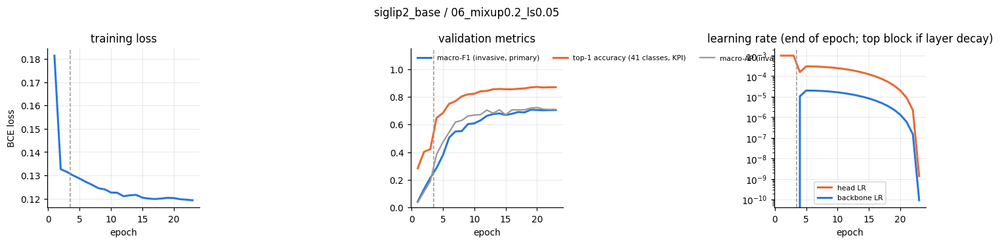

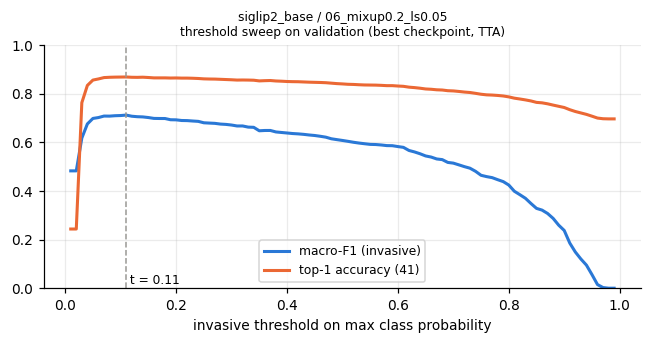

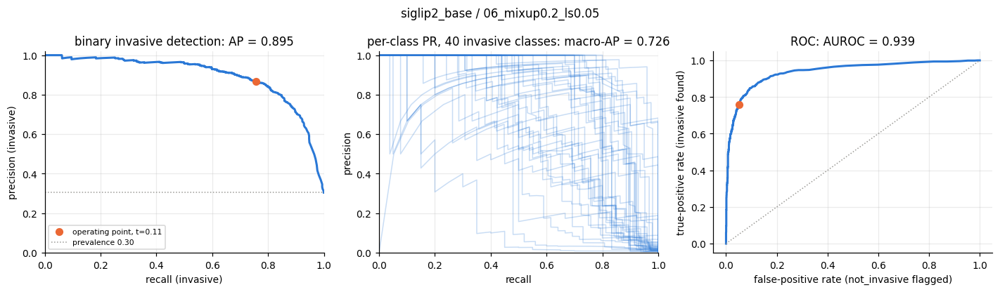

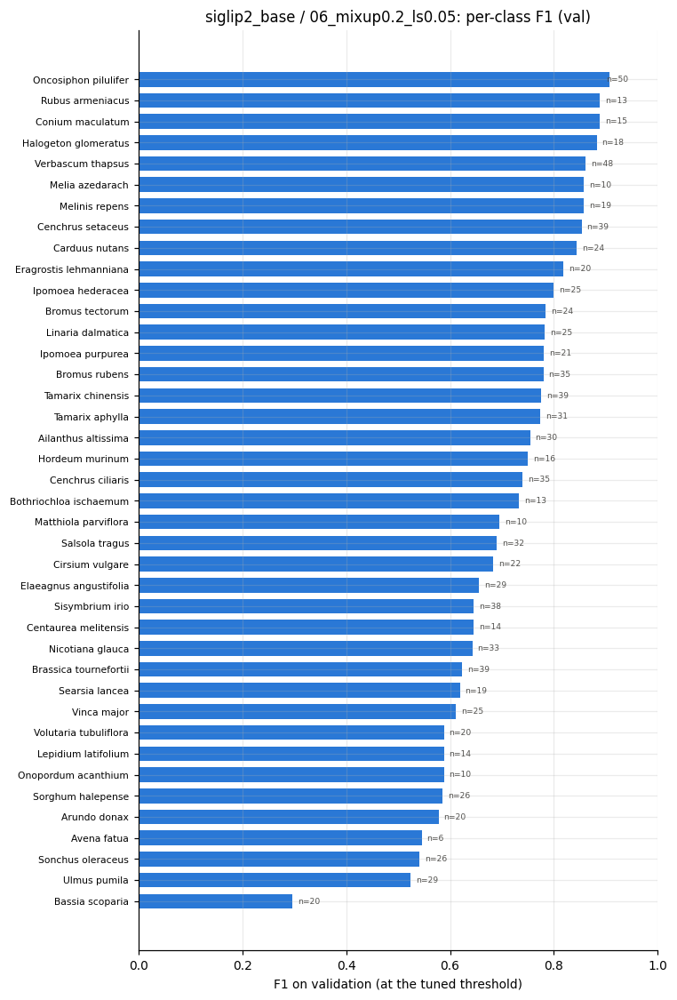

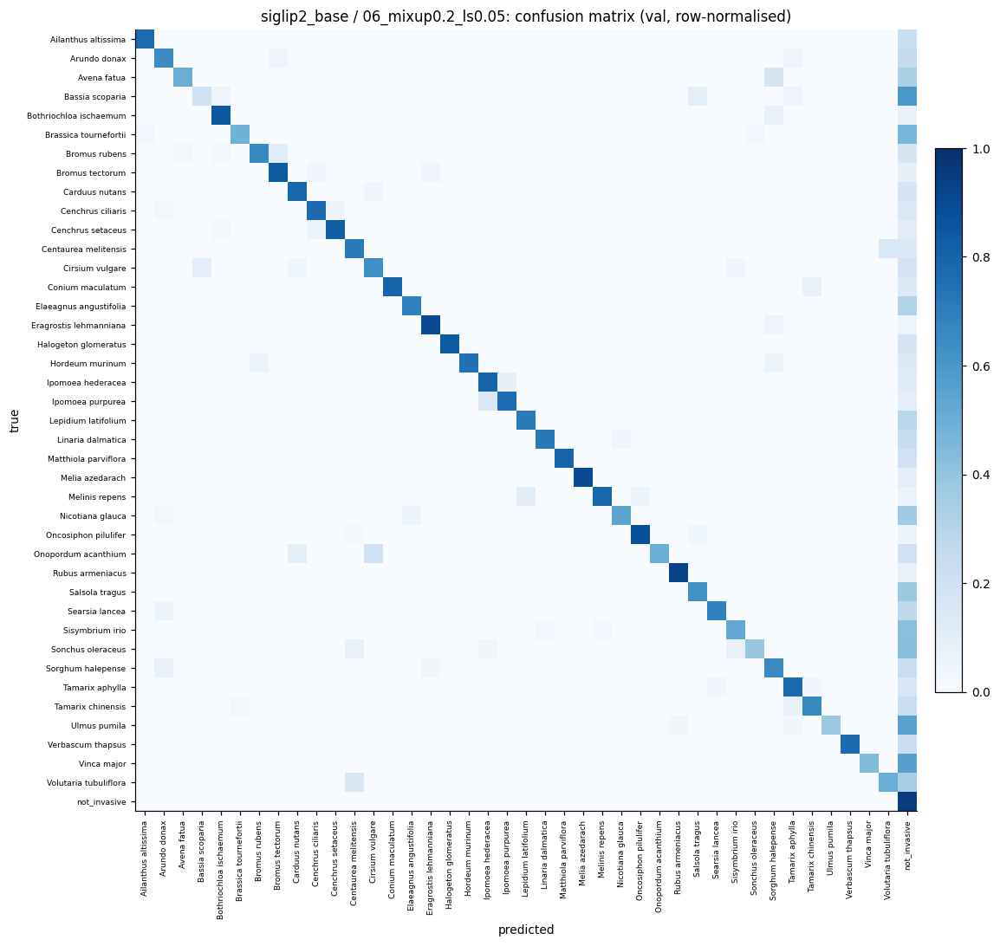

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.8690,0.7640,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 06_mixup0.2_ls0.05,0.7114,0.8680,0.7261,0.8004,0.9145,0.8681,0.7576,0.9391,0.9391,0.11
delta,-0.0024,-0.0009,-0.0379,-0.0010,-0.0112,0.0017,-0.0153,-0.0061,-0.0061,0.08


macro-F1 (invasive, primary metric) -0.0024 | top-1 accuracy (KPI) -0.0009. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '06_mixup0.2_ls0.05',
 'best_epoch': 19,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.838479971885681),
 'macro_f1_invasive': 0.7114413380622864,
 'top1_acc_all': 0.8680297136306763,
 'macro_ap_invasive': 0.7261271967779384,
 'top1_recall_invasive': 0.8004073319755601,
 'top3_recall_invasive': 0.9144602851323829,
 'threshold': 0.11,
 'bin_precision_invasive': 0.868144690781797,
 'bin_recall_invasive': 0.7576374745417516,
 'bin_f1_invasive': 0.8091353996737357,
 'bin_ap_invasive': np.float64(0.8948313781536172),
 'bin_auroc_invasive': np.float64(0.9390500514152337),
 'noninv_precision': 0.8996204133277098,
 'noninv_recall': 0.9496883348174533,
 'noninv_auroc': np.float64(0.9390500514152337),
 'macro_f1_all41': 0.7166250944137573}

In [ ]:
run_iteration("06_mixup0.2_ls0.05", {"mixup_alpha": 0.2, "label_smoothing": 0.05})

In [ ]:
# accept("06_mixup0.2_ls0.05", note="")
reject("06_mixup0.2_ls0.05", note="macro-F1 (invasive, primary metric) -0.0024")

06_mixup0.2_ls0.05: rejected. note: macro-F1 (invasive, primary metric) -0.0024
siglip2_base: 3 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49
06_mixup0.2_ls0.05,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.711441,0.868030,2026-11-04T17:00


current configuration differs from BASE_CONFIG in: nothing
reference run: 00_baseline


### 07 - Head Dropout (A/B)


===== siglip2_base / 07a_dropout_0 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/07a_dropout_0
changes vs current configuration: {'dropout': 0.0}
configuration vs BASE_CONFIG: identical
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0964 | val macro-F1 0.0448 top1 0.0294 mAP 0.0359 t=0.01 | gnorm 0.12 | 13s | elapsed 0.3m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0266 | val macro-F1 0.1599 top1 0.3594 mAP 0.1062 t=0.02 | gnorm 0.02 | 13s | elapsed 0.6m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0001 | val macro-F1 0.7114 top1 0.8708 mAP 0.7567 t=0.06 | gnorm 0.02 | 13s | elapsed 5.4m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0001 | val macro-F1 0.7111 top1 0.8705 mAP 0.7569 t=0.06 | gnorm 0.02 | 13s | elapsed 5.6m, ~0.0m left in full stage
best epoch 20: macro_f1_invasive 0.7232 | top1_acc_all 0.8755 | macro_ap_invasive 0.7660 | top1_recall_invasive 0.8106 | top3_recall_invasive 0.9297 | bin_precision_invasive 0.8951 | bin_recall_invasive 0.7556 | bin_f1_invasive 0.8194 | bin_ap_invasive 0.9065 | bin_auroc_invasive 0.9488 | noninv_precision 0.9000 | noninv_recall 0.9613 | noninv_auroc 0.9488 | macro_f1_all41 0.7282 | threshold 0.04


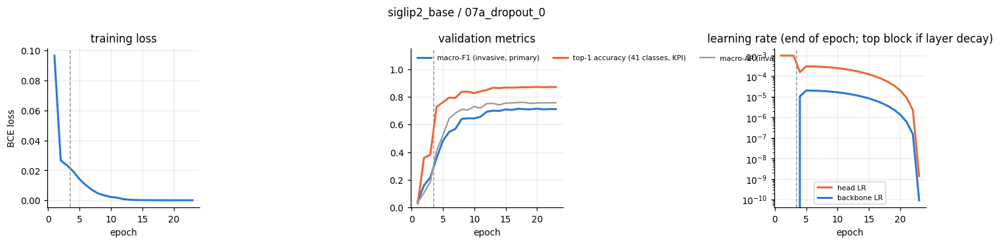

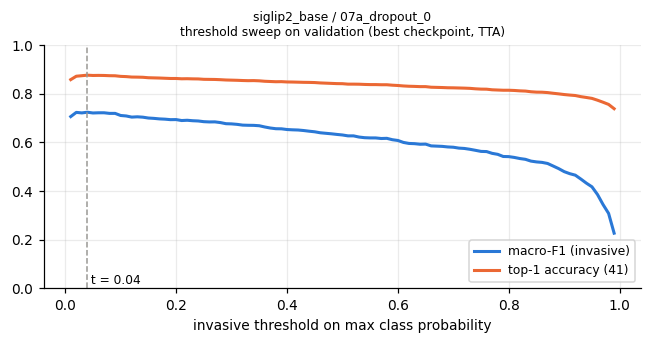

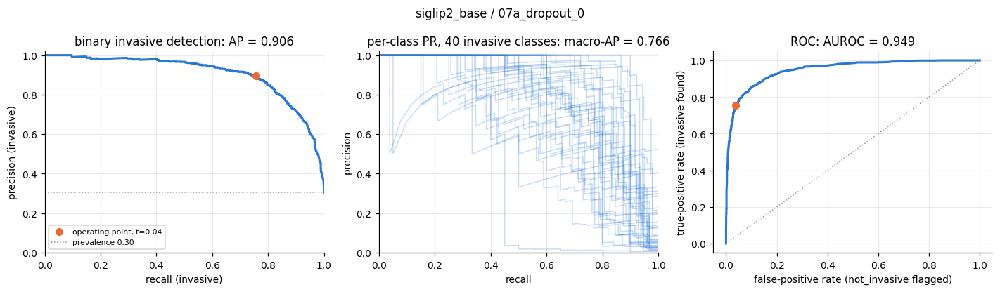

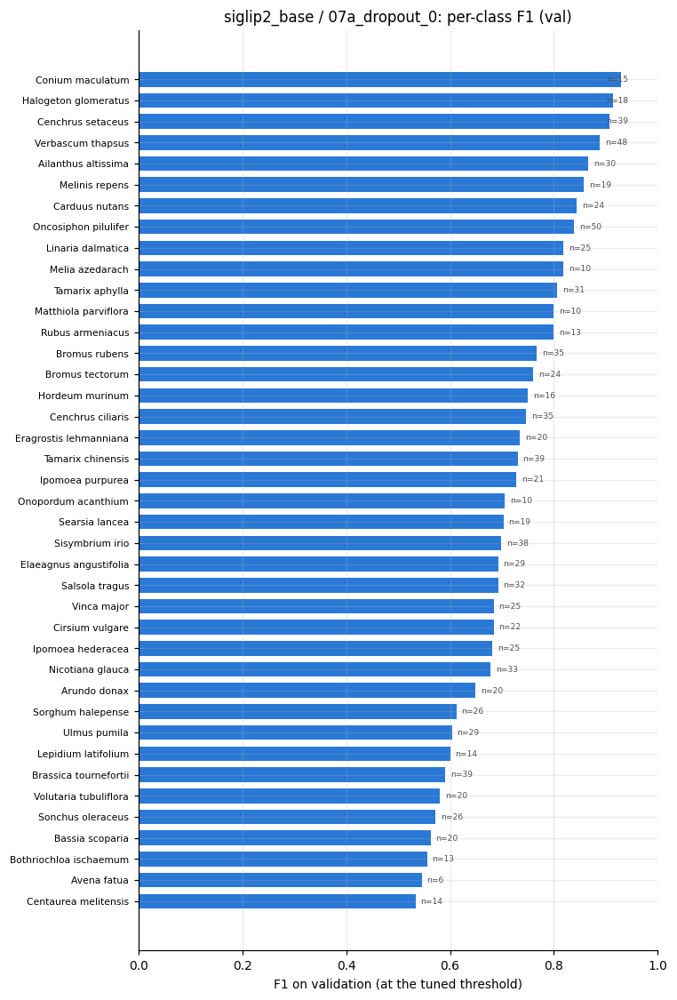

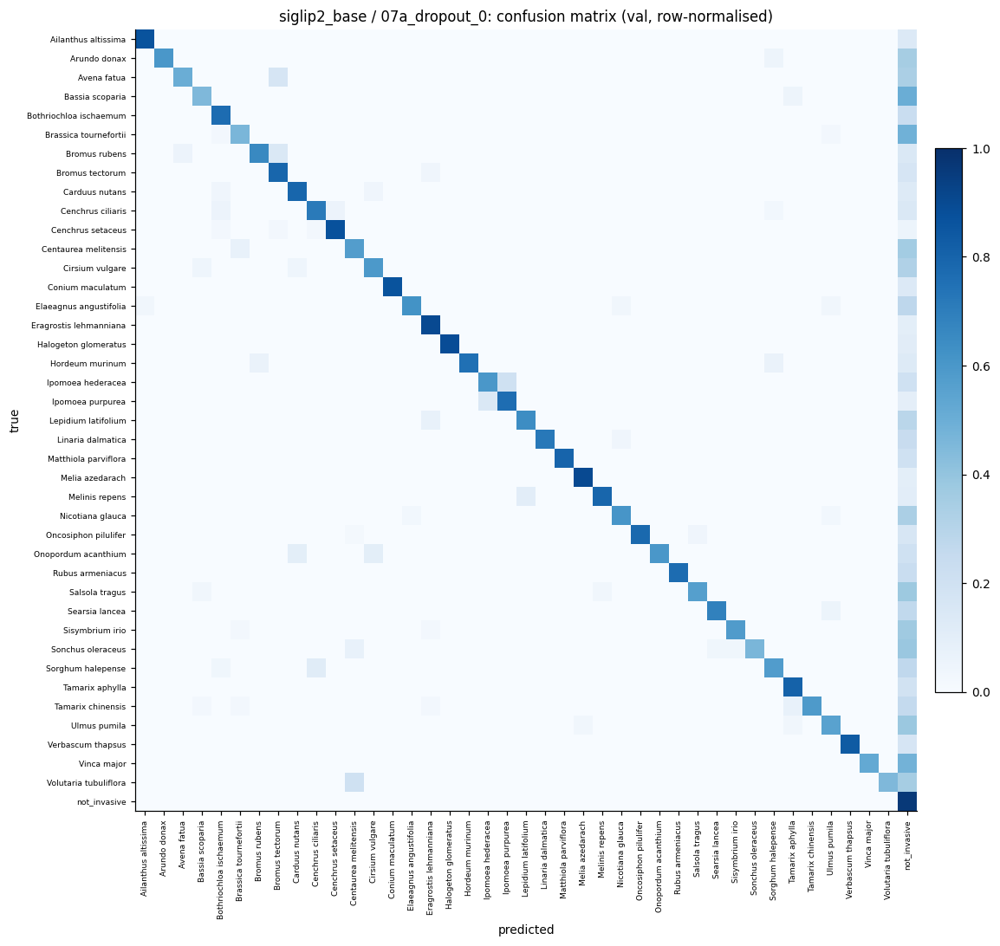

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.8690,0.764,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 07a_dropout_0,0.7232,0.8755,0.766,0.8106,0.9297,0.8951,0.7556,0.9488,0.9488,0.04
delta,0.0094,0.0065,0.002,0.0092,0.0041,0.0286,-0.0173,0.0037,0.0037,0.01


macro-F1 (invasive, primary metric) +0.0094 | top-1 accuracy (KPI) +0.0065. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '07a_dropout_0',
 'best_epoch': 20,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.8190954724947614),
 'macro_f1_invasive': 0.7231704592704773,
 'top1_acc_all': 0.875464677810669,
 'macro_ap_invasive': 0.7659553497097998,
 'top1_recall_invasive': 0.8105906313645621,
 'top3_recall_invasive': 0.929735234215886,
 'threshold': 0.04,
 'bin_precision_invasive': 0.8950542822677925,
 'bin_recall_invasive': 0.7556008146639511,
 'bin_f1_invasive': 0.819436775262286,
 'bin_ap_invasive': np.float64(0.9064558630889181),
 'bin_auroc_invasive': np.float64(0.9488497768379358),
 'noninv_precision': 0.8999583159649854,
 'noninv_recall': 0.9612644701691897,
 'noninv_auroc': np.float64(0.9488497768379359),
 'macro_f1_all41': 0.7282053828239441}

In [ ]:
run_iteration("07a_dropout_0", {"dropout": 0.0})

===== siglip2_base / 07b_dropout_0.3 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/07b_dropout_0.3
changes vs current configuration: {'dropout': 0.3}
configuration vs BASE_CONFIG: identical
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.1008 | val macro-F1 0.0325 top1 0.0263 mAP 0.0311 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


epoch 2/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/23 [frozen] loss 0.0275 | val macro-F1 0.1489 top1 0.1499 mAP 0.0876 t=0.01 | gnorm 0.02 | 12s | elapsed 0.5m, ~0.2m left in frozen stage + full stage *best*


epoch 3/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (38 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0001 | val macro-F1 0.7189 top1 0.8724 mAP 0.7596 t=0.06 | gnorm 0.02 | 13s | elapsed 5.6m, ~0.2m left in full stage


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0001 | val macro-F1 0.7184 top1 0.8721 mAP 0.7598 t=0.05 | gnorm 0.02 | 13s | elapsed 5.8m, ~0.0m left in full stage
best epoch 20: macro_f1_invasive 0.7174 | top1_acc_all 0.8711 | macro_ap_invasive 0.7665 | top1_recall_invasive 0.8055 | top3_recall_invasive 0.9318 | bin_precision_invasive 0.9065 | bin_recall_invasive 0.7210 | bin_f1_invasive 0.8032 | bin_ap_invasive 0.9095 | bin_auroc_invasive 0.9510 | noninv_precision 0.8880 | noninv_recall 0.9675 | noninv_auroc 0.9510 | macro_f1_all41 0.7225 | threshold 0.07


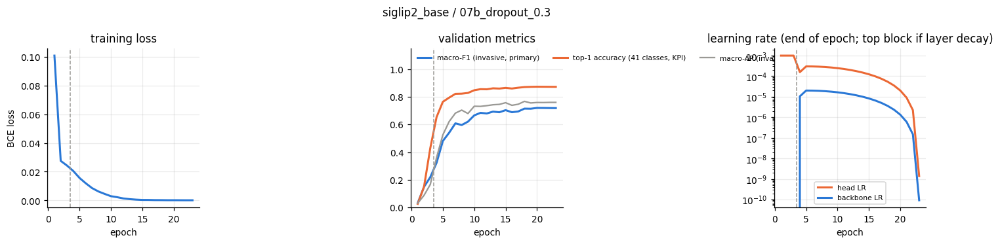

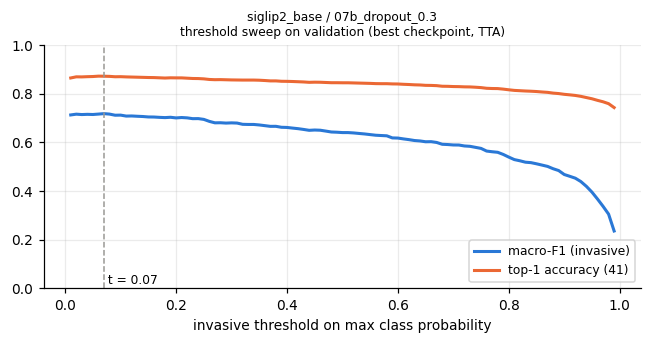

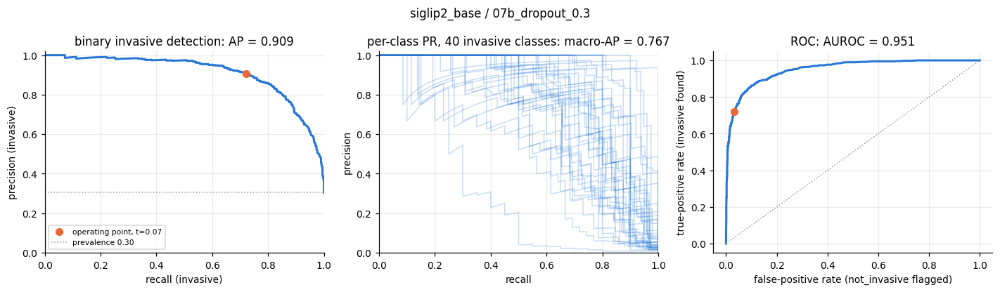

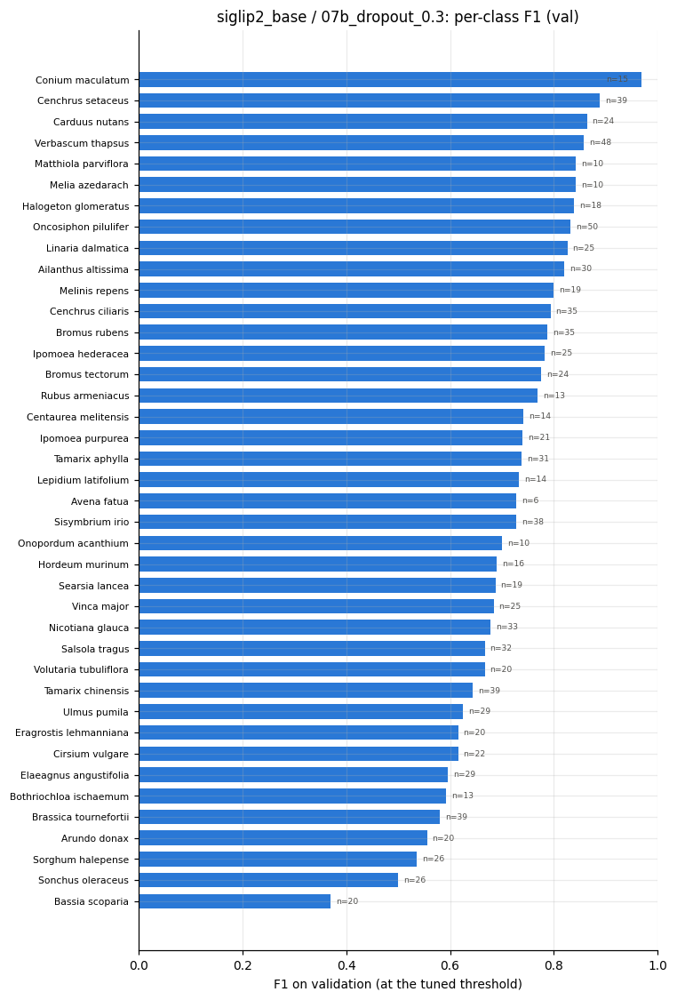

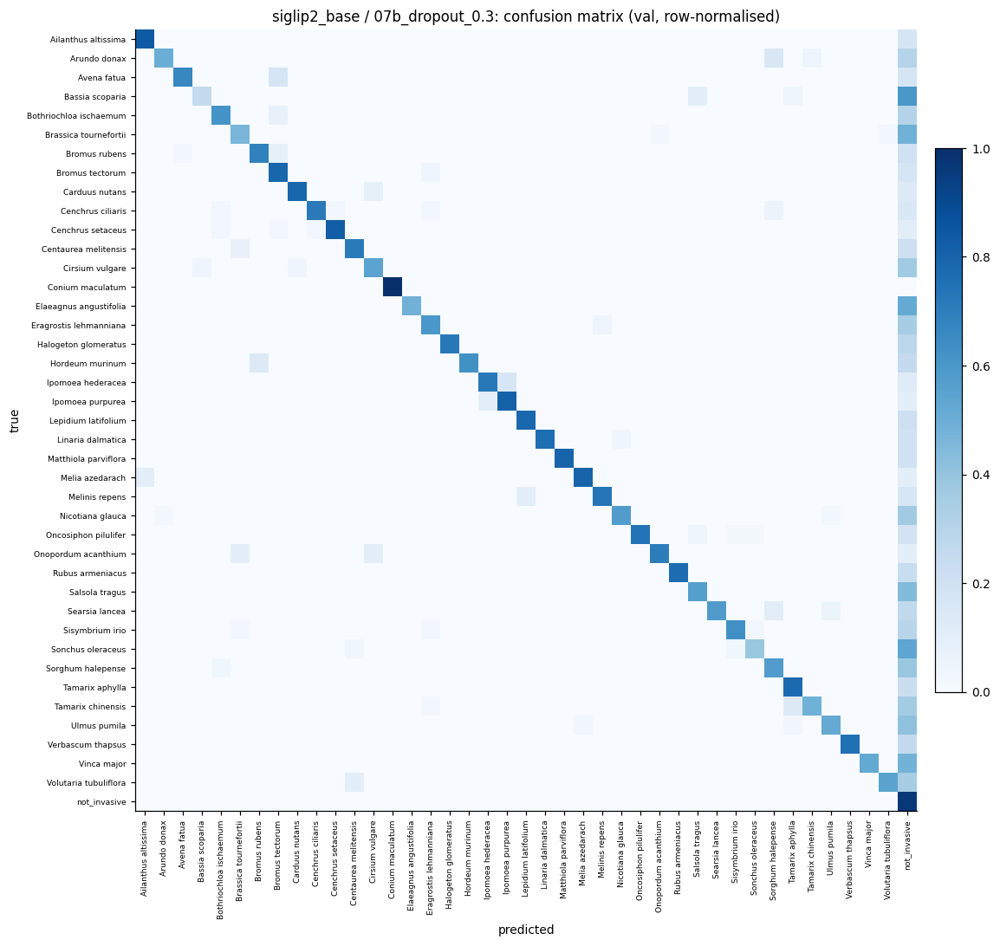

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 00_baseline,0.7138,0.8690,0.7640,0.8014,0.9257,0.8664,0.7729,0.9451,0.9451,0.03
this run: 07b_dropout_0.3,0.7174,0.8711,0.7665,0.8055,0.9318,0.9065,0.7210,0.9510,0.9510,0.07
delta,0.0036,0.0022,0.0025,0.0041,0.0061,0.0401,-0.0519,0.0059,0.0059,0.04


macro-F1 (invasive, primary metric) +0.0036 | top-1 accuracy (KPI) +0.0022. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '07b_dropout_0.3',
 'best_epoch': 20,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.8417079250017805),
 'macro_f1_invasive': 0.7173844575881958,
 'top1_acc_all': 0.8711276054382324,
 'macro_ap_invasive': 0.7665296311022196,
 'top1_recall_invasive': 0.8054989816700611,
 'top3_recall_invasive': 0.9317718940936863,
 'threshold': 0.07,
 'bin_precision_invasive': 0.9065300896286812,
 'bin_recall_invasive': 0.7209775967413442,
 'bin_f1_invasive': 0.8031764038570618,
 'bin_ap_invasive': np.float64(0.9094621472120529),
 'bin_auroc_invasive': np.float64(0.9509984258051879),
 'noninv_precision': 0.8880261544748672,
 'noninv_recall': 0.9674977738201247,
 'noninv_auroc': np.float64(0.9509984258051879),
 'macro_f1_all41': 0.7224740982055664}

In [ ]:
run_iteration("07b_dropout_0.3", {"dropout": 0.3})

In [ ]:
# Accept at most ONE of the two; reject the other (or both).
accept("07a_dropout_0", note="macro-F1 (invasive, primary metric) +0.0094 ")
# reject("07a_dropout_0", note="")
# accept("07b_dropout_0.3", note="")
reject("07b_dropout_0.3", note="")

07a_dropout_0: accepted. note: macro-F1 (invasive, primary metric) +0.0094 
siglip2_base: 4 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49
06_mixup0.2_ls0.05,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.711441,0.868030,2026-11-04T17:00
07a_dropout_0,accepted,"{""dropout"": 0.0}",0.723170,0.875465,2026-11-04T17:14


current configuration differs from BASE_CONFIG in: {'dropout': 0.0}
reference run: 07a_dropout_0
07b_dropout_0.3: rejected.
siglip2_base: 5 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49
06_mixup0.2_ls0.05,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.711441,0.868030,2026-11-04T17:00
07a_dropout_0,accepted,"{""dropout"": 0.0}",0.723170,0.875465,2026-11-04T17:14
07b_dropout_0.3,rejected,"{""dropout"": 0.3}",0.717384,0.871128,2026-11-04T17:14


current configuration differs from BASE_CONFIG in: {'dropout': 0.0}
reference run: 07a_dropout_0


### 08 — Validation preprocessing without a crop


===== siglip2_base / 08_val_resize_224 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/08_val_resize_224
changes vs current configuration: {'val_resize': 224}
configuration vs BASE_CONFIG: {'dropout': 0.0}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0


decoding train images:   0%|          | 0/7342 [00:00<?, ?img/s]

decoding val images:   0%|          | 0/3228 [00:00<?, ?img/s]

image cache: 7342 train images at presize 256 + 3228 val crops of 224x224 = 2.35 GB in RAM (43s)
23 epochs (3 frozen + 20 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/23 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/23 [frozen] loss 0.0964 | val macro-F1 0.0369 top1 0.1208 mAP 0.0315 t=0.02 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


... (41 outputs left out)

epoch 22/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 22/23 [full  ] loss 0.0001 | val macro-F1 0.7074 top1 0.8680 mAP 0.7543 t=0.07 | gnorm 0.02 | 13s | elapsed 5.5m, ~0.2m left in full stage *best*


epoch 23/23 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 23/23 [full  ] loss 0.0001 | val macro-F1 0.7066 top1 0.8680 mAP 0.7539 t=0.07 | gnorm 0.02 | 13s | elapsed 5.7m, ~0.0m left in full stage
best epoch 22: macro_f1_invasive 0.7025 | top1_acc_all 0.8668 | macro_ap_invasive 0.7579 | top1_recall_invasive 0.8055 | top3_recall_invasive 0.9328 | bin_precision_invasive 0.8830 | bin_recall_invasive 0.7301 | bin_f1_invasive 0.7993 | bin_ap_invasive 0.9065 | bin_auroc_invasive 0.9498 | noninv_precision 0.8903 | noninv_recall 0.9577 | noninv_auroc 0.9498 | macro_f1_all41 0.7079 | threshold 0.04


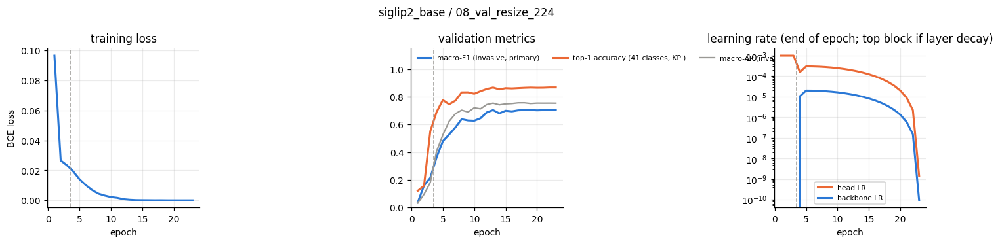

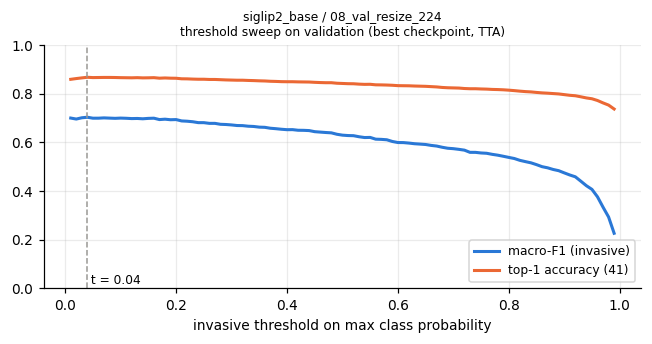

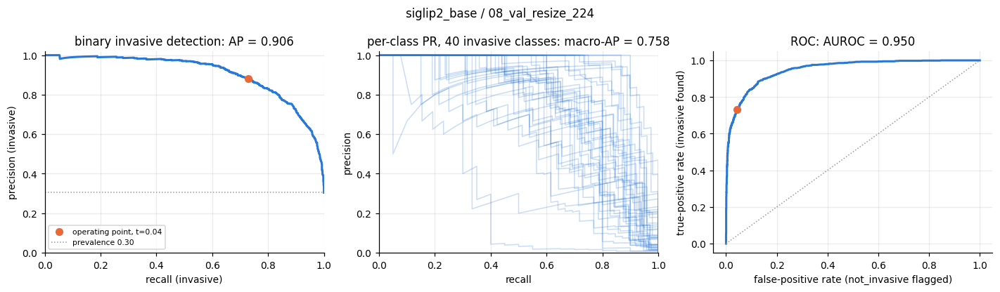

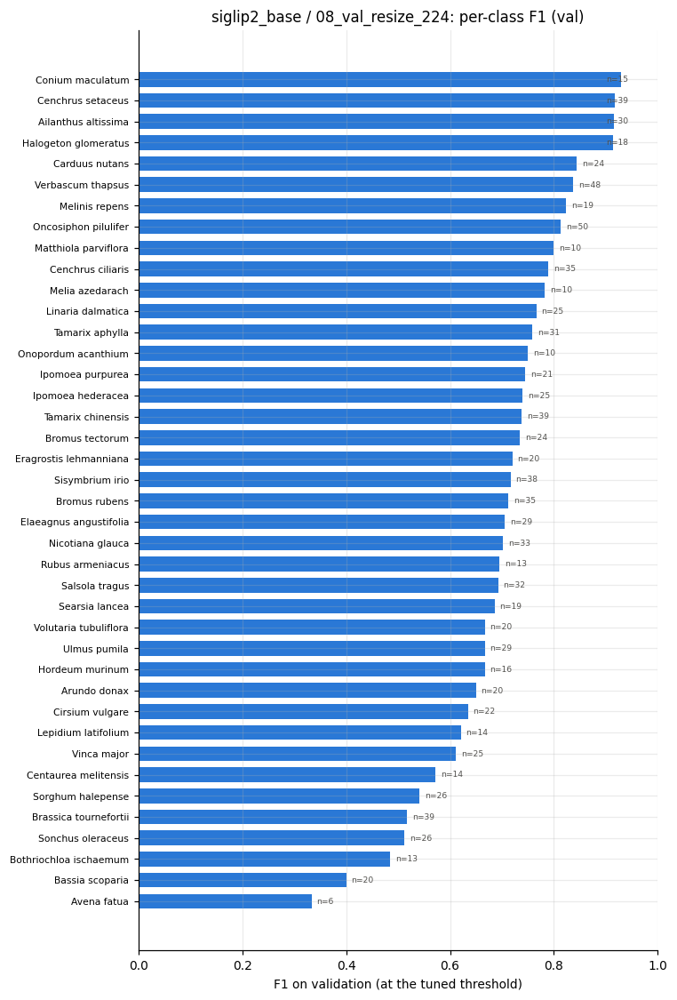

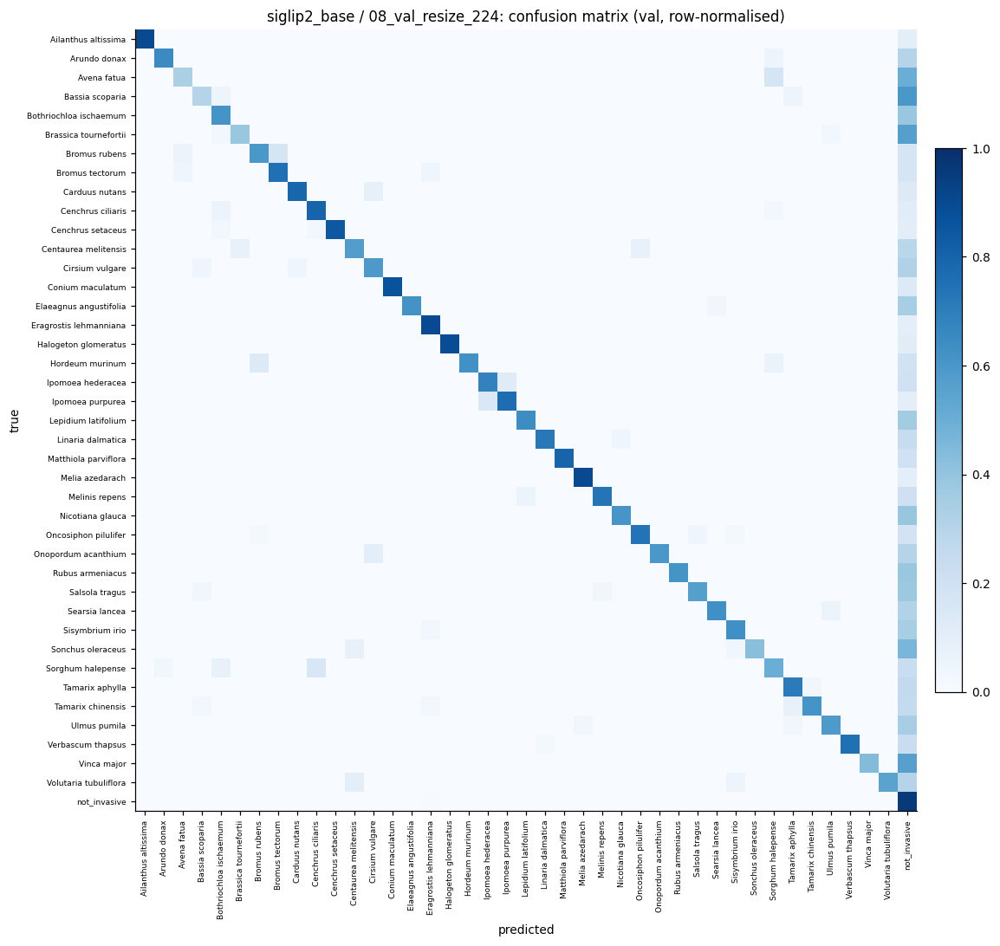

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 07a_dropout_0,0.7232,0.8755,0.7660,0.8106,0.9297,0.8951,0.7556,0.9488,0.9488,0.04
this run: 08_val_resize_224,0.7025,0.8668,0.7579,0.8055,0.9328,0.8830,0.7301,0.9498,0.9498,0.04
delta,-0.0206,-0.0087,-0.0081,-0.0051,0.0031,-0.0120,-0.0255,0.0010,0.0010,0.00


macro-F1 (invasive, primary metric) -0.0206 | top-1 accuracy (KPI) -0.0087. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '08_val_resize_224',
 'best_epoch': 22,
 'epochs': 23,
 'tta_hflip': True,
 'train_minutes': np.float64(4.849778628349304),
 'macro_f1_invasive': 0.7025306820869446,
 'top1_acc_all': 0.8667905926704407,
 'macro_ap_invasive': 0.7578872714486211,
 'top1_recall_invasive': 0.8054989816700611,
 'top3_recall_invasive': 0.9327902240325866,
 'threshold': 0.04,
 'bin_precision_invasive': 0.8830049261083743,
 'bin_recall_invasive': 0.730142566191446,
 'bin_f1_invasive': 0.7993311036789298,
 'bin_ap_invasive': np.float64(0.9064634667140291),
 'bin_auroc_invasive': np.float64(0.9498452102221102),
 'noninv_precision': 0.8903145695364238,
 'noninv_recall': 0.9577025823686554,
 'noninv_auroc': np.float64(0.9498452102221102),
 'macro_f1_all41': 0.7079026103019714}

In [ ]:
run_iteration("08_val_resize_224", {"val_resize": 224})

In [ ]:
# accept("08_val_resize_224", note="")
reject("08_val_resize_224", note="macro-F1 (invasive, primary metric) -0.0206 ")

08_val_resize_224: rejected. note: macro-F1 (invasive, primary metric) -0.0206 
siglip2_base: 6 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49
06_mixup0.2_ls0.05,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.711441,0.868030,2026-11-04T17:00
07a_dropout_0,accepted,"{""dropout"": 0.0}",0.723170,0.875465,2026-11-04T17:14
07b_dropout_0.3,rejected,"{""dropout"": 0.3}",0.717384,0.871128,2026-11-04T17:14
08_val_resize_224,rejected,"{""val_resize"": 224}",0.702531,0.866791,2026-11-04T17:33


current configuration differs from BASE_CONFIG in: {'dropout': 0.0}
reference run: 07a_dropout_0


### 09 - Longer training

===== siglip2_base / 09_full_epochs_30 -> /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/09_full_epochs_30
changes vs current configuration: {'full_epochs': 30}
configuration vs BASE_CONFIG: {'dropout': 0.0}
siglip2_base: backbone 92.9M params, head 30.8K params, feat_dim 768 | timm vit_base_patch16_siglip_224.v2_webli, pool=map, drop_path=0.0
33 epochs (3 frozen + 30 full) x 114 batches of 64 | validation: 3228 images in 26 batches


epoch 1/33 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  1/33 [frozen] loss 0.0964 | val macro-F1 0.0448 top1 0.0294 mAP 0.0359 t=0.01 | gnorm 0.12 | 13s | elapsed 0.2m, ~0.4m left in frozen stage + full stage *best*


epoch 2/33 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

ep  2/33 [frozen] loss 0.0266 | val macro-F1 0.1599 top1 0.3594 mAP 0.1062 t=0.02 | gnorm 0.02 | 13s | elapsed 0.4m, ~0.2m left in frozen stage + full stage *best*


epoch 3/33 (frozen):   0%|          | 0/114 [00:00<?, ?batch/s]

... (58 outputs left out)

epoch 32/33 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 32/33 [full  ] loss 0.0000 | val macro-F1 0.7049 top1 0.8643 mAP 0.7452 t=0.01 | gnorm 0.01 | 13s | elapsed 7.9m, ~0.2m left in full stage


epoch 33/33 (full):   0%|          | 0/114 [00:00<?, ?batch/s]

ep 33/33 [full  ] loss 0.0000 | val macro-F1 0.7048 top1 0.8646 mAP 0.7452 t=0.01 | gnorm 0.01 | 13s | elapsed 8.1m, ~0.0m left in full stage
best epoch 31: macro_f1_invasive 0.7114 | top1_acc_all 0.8702 | macro_ap_invasive 0.7504 | top1_recall_invasive 0.8086 | top3_recall_invasive 0.9287 | bin_precision_invasive 0.8824 | bin_recall_invasive 0.7485 | bin_f1_invasive 0.8099 | bin_ap_invasive 0.9064 | bin_auroc_invasive 0.9476 | noninv_precision 0.8969 | noninv_recall 0.9564 | noninv_auroc 0.9476 | macro_f1_all41 0.7167 | threshold 0.02


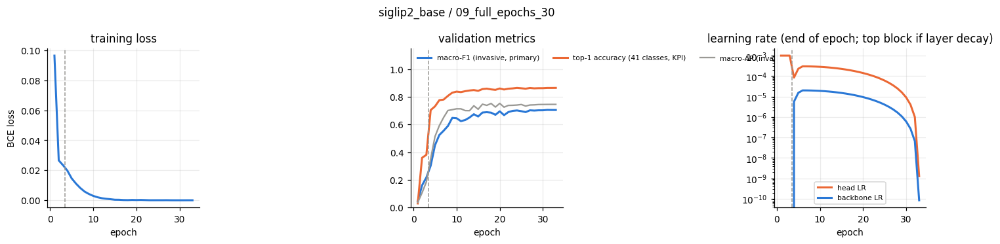

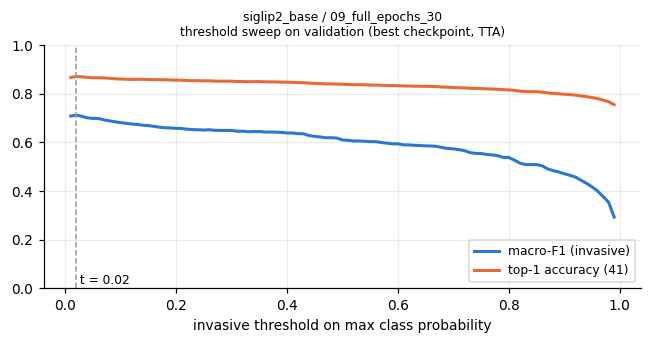

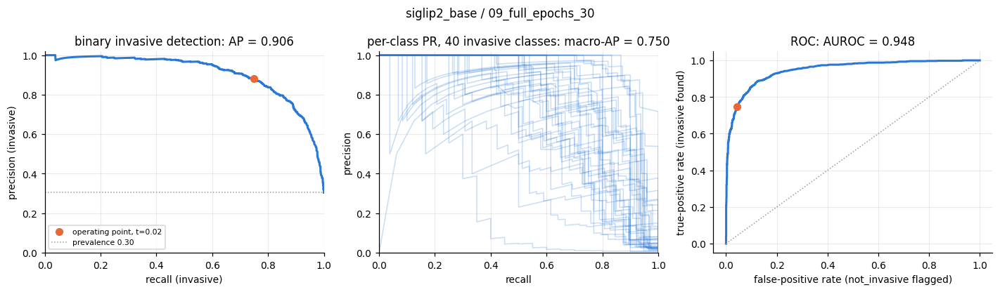

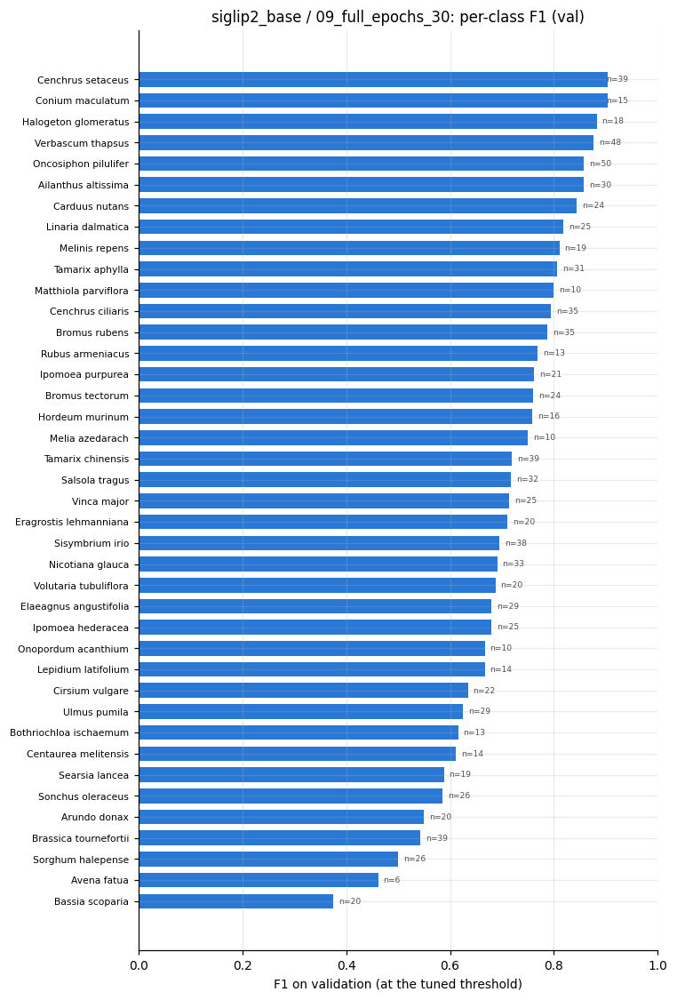

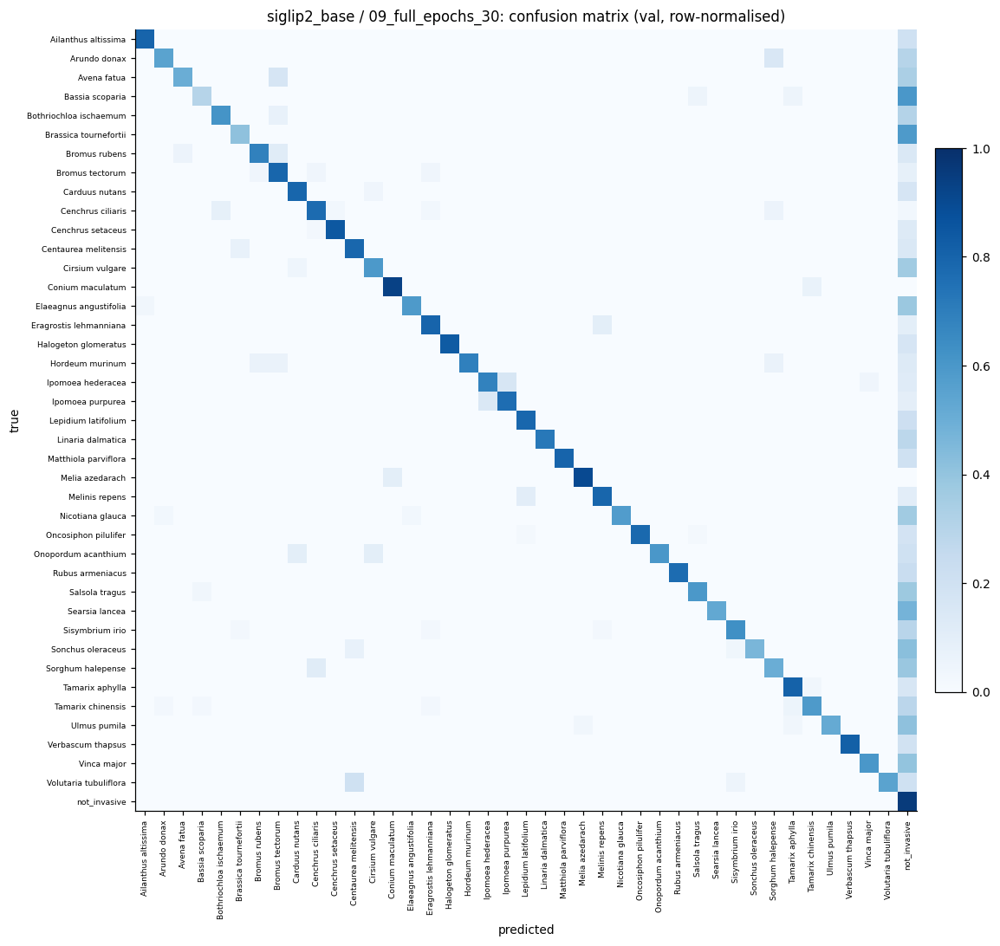

,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
reference: 07a_dropout_0,0.7232,0.8755,0.7660,0.8106,0.9297,0.8951,0.7556,0.9488,0.9488,0.04
this run: 09_full_epochs_30,0.7114,0.8702,0.7504,0.8086,0.9287,0.8824,0.7485,0.9476,0.9476,0.02
delta,-0.0117,-0.0053,-0.0156,-0.0020,-0.0010,-0.0127,-0.0071,-0.0013,-0.0013,-0.02


macro-F1 (invasive, primary metric) -0.0117 | top-1 accuracy (KPI) -0.0053. Design rule: accept if macro-F1 clearly improves and top-1 does not drop substantially. Your call: accept(name) or reject(name).


{'model': 'siglip2_base',
 'iteration': '09_full_epochs_30',
 'best_epoch': 31,
 'epochs': 33,
 'tta_hflip': True,
 'train_minutes': np.float64(6.963027862707774),
 'macro_f1_invasive': 0.7114425897598267,
 'top1_acc_all': 0.8701982498168945,
 'macro_ap_invasive': 0.7503574671479516,
 'top1_recall_invasive': 0.8085539714867617,
 'top3_recall_invasive': 0.9287169042769857,
 'threshold': 0.02,
 'bin_precision_invasive': 0.8823529411764706,
 'bin_recall_invasive': 0.7484725050916496,
 'bin_f1_invasive': 0.8099173553719008,
 'bin_ap_invasive': np.float64(0.906376558972092),
 'bin_auroc_invasive': np.float64(0.947560768816434),
 'noninv_precision': 0.8968684759916493,
 'noninv_recall': 0.956366874443455,
 'noninv_auroc': np.float64(0.9475607688164339),
 'macro_f1_all41': 0.7166674733161926}

In [ ]:
run_iteration("09_full_epochs_30", {"full_epochs": 30})

In [ ]:
# accept("09_full_epochs_30", note="")
reject("09_full_epochs_30", note="macro-F1 (invasive, primary metric) -0.0117")

09_full_epochs_30: rejected. note: macro-F1 (invasive, primary metric) -0.0117
siglip2_base: 7 decisions recorded in /content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs/siglip2_base/decisions.json


,decision,overrides,macro_f1_invasive,top1_acc_all,when
name,,,,,
00_baseline,accepted,{},0.713813,0.868959,2026-11-04T04:00
05_drop_path_0.1,rejected,"{""backbone_kwargs"": {""drop_path_rate"": 0.1}}",0.704009,0.865242,2026-11-04T16:49
06_mixup0.2_ls0.05,rejected,"{""mixup_alpha"": 0.2, ""label_smoothing"": 0.05}",0.711441,0.868030,2026-11-04T17:00
07a_dropout_0,accepted,"{""dropout"": 0.0}",0.723170,0.875465,2026-11-04T17:14
07b_dropout_0.3,rejected,"{""dropout"": 0.3}",0.717384,0.871128,2026-11-04T17:14
08_val_resize_224,rejected,"{""val_resize"": 224}",0.702531,0.866791,2026-11-04T17:33
09_full_epochs_30,rejected,"{""full_epochs"": 30}",0.711443,0.870198,2026-11-04T17:43


current configuration differs from BASE_CONFIG in: {'dropout': 0.0}
reference run: 07a_dropout_0
